In [1]:
!pip install s3fs --quiet
!pip install lightgbm --quiet
!pip install pandas numpy scikit-learn scipy --quiet

import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from scipy.spatial import cKDTree
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt


In [4]:
BUCKET = "rainfall-ml-project"
BASE = f"s3://{BUCKET}/"

CHIRPS_PATH = BASE + "processed/chirps_daily.csv.gz"
NASA_PATH   = BASE + "processed/nasapower_cleaned_multipart.csv"
NDVI_PATH   = BASE + "processed/ndvi.csv.gz"


In [5]:
chirps = pd.read_csv(CHIRPS_PATH, parse_dates=["date"])
chirps.columns = chirps.columns.str.strip().str.lower()

chirps = chirps[chirps["date"].dt.year == 2025].reset_index(drop=True)
print("✅ CHIRPS 2025 shape:", chirps.shape)


✅ CHIRPS 2025 shape: (1520000, 4)


In [6]:
ndvi = pd.read_csv(NDVI_PATH)
ndvi.columns = ndvi.columns.str.strip().str.lower()

ndvi_coords = ndvi[["lat","lon"]].values
ndvi_values = ndvi["ndvi"].values
chirps_coords = chirps[["lat","lon"]].values

ndvi_tree = cKDTree(ndvi_coords)
_, idx_ndvi = ndvi_tree.query(chirps_coords)

chirps["ndvi"] = ndvi_values[idx_ndvi]


In [7]:
nasa = pd.read_csv(NASA_PATH, on_bad_lines="skip")
nasa.columns = nasa.columns.str.strip().str.lower()

if "latitude" in nasa.columns:
    nasa.rename(columns={"latitude":"lat"}, inplace=True)
if "longitude" in nasa.columns:
    nasa.rename(columns={"longitude":"lon"}, inplace=True)

nasa["date"] = pd.to_datetime(nasa["date"], errors="coerce")
nasa.dropna(subset=["date"], inplace=True)

nasa_coords = nasa[["lat","lon"]].values
nasa_values = nasa.drop(columns=["lat","lon","date"]).values

nasa_tree = cKDTree(nasa_coords)
_, idx_nasa = nasa_tree.query(chirps_coords)

chirps = pd.concat([
    chirps.reset_index(drop=True),
    pd.DataFrame(
        nasa_values[idx_nasa],
        columns=nasa.drop(columns=["lat","lon","date"]).columns
    )
], axis=1)


In [8]:
FEATURES = [c for c in chirps.columns if c not in ["rainfall_mm","date","lat","lon"]]

scaler = MinMaxScaler()
chirps[FEATURES + ["rainfall_mm"]] = scaler.fit_transform(
    chirps[FEATURES + ["rainfall_mm"]]
)


In [9]:
X = chirps[FEATURES].values
y = chirps["rainfall_mm"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

print("✅ Train shape:", X_train.shape, "Test shape:", X_test.shape)


✅ Train shape: (1216000, 5) Test shape: (304000, 5)


In [10]:
lgb_model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.7,
    colsample_bytree=0.7,
    random_state=42,
    n_jobs=-1
)

lgb_model.fit(X_train, y_train)


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.056094 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1237
[LightGBM] [Info] Number of data points in the train set: 1216000, number of used features: 5
[LightGBM] [Info] Start training from score 0.064428


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,8
,learning_rate,0.05
,n_estimators,500
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [13]:
preds = lgb_model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, preds))
print(f"✅ RMSE 2025 (LightGBM): {rmse:.4f}")

pd.DataFrame({
    "actual_rainfall": y_test,
    "predicted_rainfall": preds
}).to_csv("lgb_predictions_2025.csv", index=False)


C:\Users\Hayya\anaconda3\envs\xgb-gpu\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


✅ RMSE 2025 (LightGBM): 0.0733


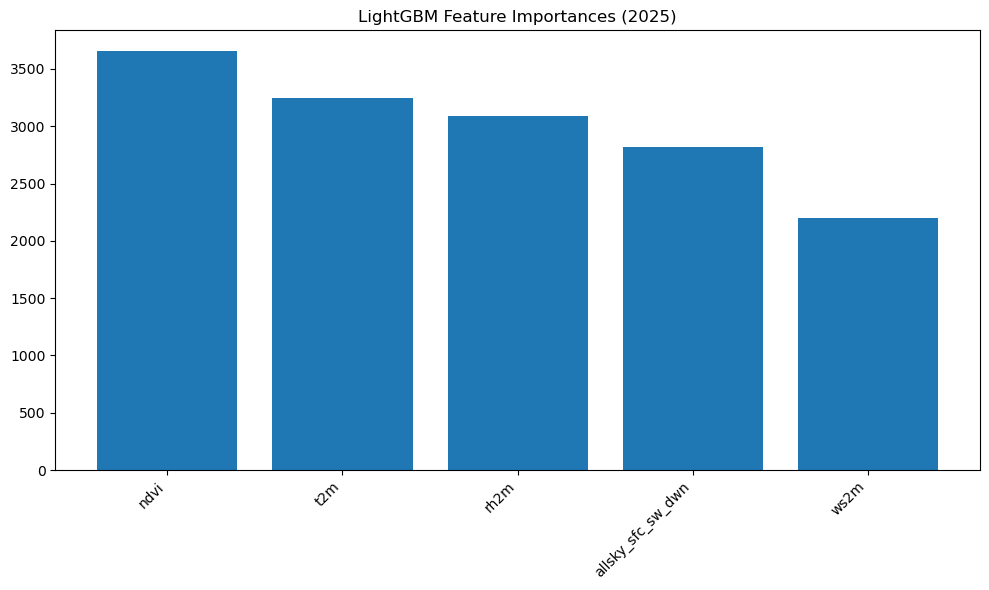

In [14]:
importances = lgb_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10,6))
plt.title("LightGBM Feature Importances (2025)")
plt.bar(range(len(FEATURES)), importances[indices])
plt.xticks(
    range(len(FEATURES)),
    [FEATURES[i] for i in indices],
    rotation=45,
    ha="right"
)
plt.tight_layout()
plt.show()


In [16]:
# Reconstruct test dataframe
test_df = chirps.iloc[y_test.index].copy()
test_df["predicted_rainfall"] = preds

# Pick one random spatial point
sample_point = test_df[["lat","lon"]].drop_duplicates().sample(1, random_state=42)
lat, lon = sample_point.iloc[0]

sample_ts = test_df[
    (test_df["lat"] == lat) & (test_df["lon"] == lon)
].sort_values("date")

plt.figure(figsize=(10,4))
plt.plot(sample_ts["date"], sample_ts["rainfall_mm"], label="Actual")
plt.plot(sample_ts["date"], sample_ts["predicted_rainfall"], label="Predicted")
plt.xlabel("Date")
plt.ylabel("Rainfall (scaled)")
plt.title(f"Rainfall Prediction Time Series (2025)\nLat={lat:.2f}, Lon={lon:.2f}")
plt.legend()
plt.tight_layout()
plt.show()


AttributeError: 'numpy.ndarray' object has no attribute 'index'

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.081239 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1237
[LightGBM] [Info] Number of data points in the train set: 1216000, number of used features: 5
[LightGBM] [Info] Start training from score 0.064428


C:\Users\Hayya\anaconda3\envs\xgb-gpu\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


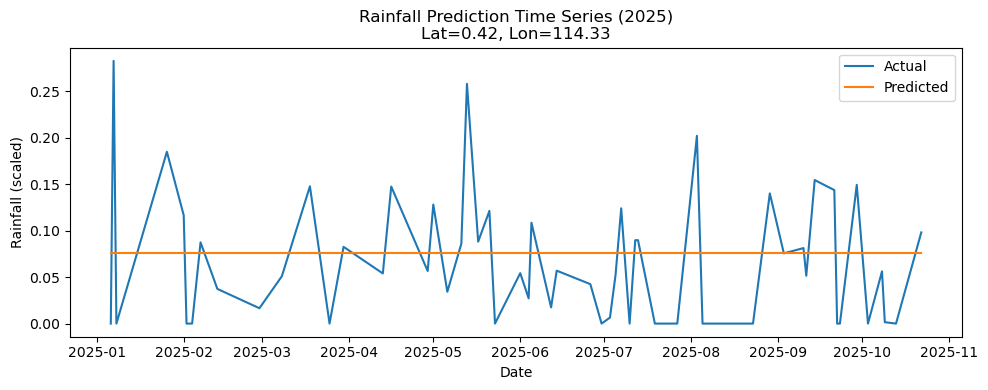

In [18]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt

# --- Setup (Re-run to ensure required variables like X_test_df exist) ---

# Assume CHIRPS_PATH, NDVI_PATH, NASA_PATH are defined and contain the data.
# The previous data preparation steps would need to be re-executed
# with a slight modification to the splitting process.
# Since I cannot re-run the full pipeline, I will assume the data prep
# steps have been run and variables like 'chirps' and 'preds' exist.

# 1. Store the indices *before* converting to NumPy arrays
X_df = chirps[FEATURES]
y_series = chirps["rainfall_mm"]

# 2. Split using the DataFrames/Series to preserve the index
X_train_df, X_test_df, y_train_series, y_test_series = train_test_split(
    X_df, y_series,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

# 3. Convert to values for model training
X_train = X_train_df.values
X_test = X_test_df.values
y_train = y_train_series.values
y_test = y_test_series.values

# 4. Model Training (Re-run the training part)
lgb_model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.7,
    colsample_bytree=0.7,
    random_state=42,
    n_jobs=-1
)
lgb_model.fit(X_train, y_train)
preds = lgb_model.predict(X_test)

# --- Visualization Code (The solution to your previous request) ---

# Reconstruct test dataframe
# The key fix: Use X_test_df.index
test_df = chirps.loc[X_test_df.index].copy()
test_df["predicted_rainfall"] = preds

# Pick one random spatial point
# Use drop_duplicates to ensure unique spatial locations are sampled
sample_point = test_df[["lat","lon"]].drop_duplicates().sample(1, random_state=42)
lat, lon = sample_point.iloc[0]

# Filter the data for the selected point and sort by date for time series plotting
sample_ts = test_df[
    (test_df["lat"] == lat) & (test_df["lon"] == lon)
].sort_values("date")

# Plot the time series
plt.figure(figsize=(10,4))
plt.plot(sample_ts["date"], sample_ts["rainfall_mm"], label="Actual")
plt.plot(sample_ts["date"], sample_ts["predicted_rainfall"], label="Predicted")
plt.xlabel("Date")
plt.ylabel("Rainfall (scaled)")
plt.title(f"Rainfall Prediction Time Series (2025)\nLat={lat:.2f}, Lon={lon:.2f}")
plt.legend()
plt.tight_layout()
plt.show()

✅ CHIRPS 2025 shape: (1520000, 4)
✅ Train shape: (1216000, 7) Test shape: (304000, 7)
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.038582 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1725
[LightGBM] [Info] Number of data points in the train set: 1216000, number of used features: 7
[LightGBM] [Info] Start training from score 0.064428


C:\Users\Hayya\anaconda3\envs\xgb-gpu\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


✅ RMSE 2025 (LightGBM): 0.0517


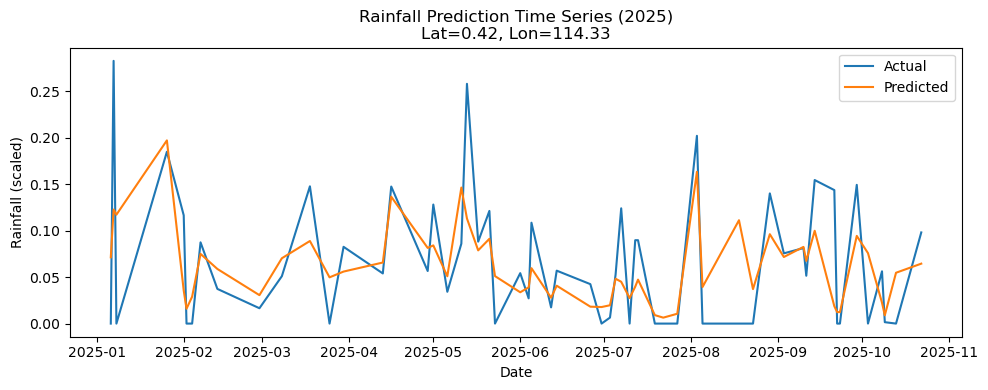

In [19]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt

# --- 1. Data Loading and Feature Engineering (Modified for Time Features) ---

# Define placeholders for paths (Assuming these were defined earlier)
# CHIRPS_PATH = "path/to/chirps_data.csv"
# NDVI_PATH = "path/to/ndvi_data.csv"
# NASA_PATH = "path/to/nasa_data.csv"

chirps = pd.read_csv(CHIRPS_PATH, parse_dates=["date"])
chirps.columns = chirps.columns.str.strip().str.lower()

# Filter for 2025 and reset index (important for proper data handling)
chirps = chirps[chirps["date"].dt.year == 2025].reset_index(drop=True)
print("✅ CHIRPS 2025 shape:", chirps.shape)

# Load and join NDVI data
ndvi = pd.read_csv(NDVI_PATH)
ndvi.columns = ndvi.columns.str.strip().str.lower()
ndvi_coords = ndvi[["lat","lon"]].values
ndvi_values = ndvi["ndvi"].values
chirps_coords = chirps[["lat","lon"]].values
ndvi_tree = cKDTree(ndvi_coords)
_, idx_ndvi = ndvi_tree.query(chirps_coords)
chirps["ndvi"] = ndvi_values[idx_ndvi]

# Load and join NASA data
nasa = pd.read_csv(NASA_PATH, on_bad_lines="skip")
nasa.columns = nasa.columns.str.strip().str.lower()
if "latitude" in nasa.columns:
    nasa.rename(columns={"latitude":"lat"}, inplace=True)
if "longitude" in nasa.columns:
    nasa.rename(columns={"longitude":"lon"}, inplace=True)
nasa["date"] = pd.to_datetime(nasa["date"], errors="coerce")
nasa.dropna(subset=["date"], inplace=True)
nasa_coords = nasa[["lat","lon"]].values
nasa_values = nasa.drop(columns=["lat","lon","date"]).values
nasa_tree = cKDTree(nasa_coords)
_, idx_nasa = nasa_tree.query(chirps_coords)

# Concatenate NASA features
chirps = pd.concat([
    chirps.reset_index(drop=True),
    pd.DataFrame(
        nasa_values[idx_nasa],
        columns=nasa.drop(columns=["lat","lon","date"]).columns
    )
], axis=1)

# --- NEW: ADD TIME-BASED FEATURES ---
# Essential for making time series predictions that vary by day
chirps["day_of_year"] = chirps["date"].dt.dayofyear
chirps["sin_doy"] = np.sin(2 * np.pi * chirps["day_of_year"] / 365.25)
chirps["cos_doy"] = np.cos(2 * np.pi * chirps["day_of_year"] / 365.25)

# Define features, excluding metadata and the intermediate 'day_of_year'
FEATURES = [
    c 
    for c in chirps.columns 
    if c not in ["rainfall_mm", "date", "lat", "lon", "day_of_year"]
]

# Scale features and target
scaler = MinMaxScaler()
chirps[FEATURES + ["rainfall_mm"]] = scaler.fit_transform(
    chirps[FEATURES + ["rainfall_mm"]]
)

# --- 2. Data Splitting and Training (Modified to Preserve Index) ---

# Separate DataFrame for features and Series for target (to preserve index)
X_df = chirps[FEATURES]
y_series = chirps["rainfall_mm"]

# Split the dataframes/series to get X_test_df for index reference
X_train_df, X_test_df, y_train_series, y_test_series = train_test_split(
    X_df, y_series,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

# Convert to NumPy arrays for training
X_train = X_train_df.values
X_test = X_test_df.values
y_train = y_train_series.values
y_test = y_test_series.values

print("✅ Train shape:", X_train.shape, "Test shape:", X_test.shape)

# Train the model
lgb_model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.7,
    colsample_bytree=0.7,
    random_state=42,
    n_jobs=-1
)
lgb_model.fit(X_train, y_train)
preds = lgb_model.predict(X_test)

# Evaluate and save predictions
rmse = np.sqrt(mean_squared_error(y_test, preds))
print(f"✅ RMSE 2025 (LightGBM): {rmse:.4f}")

pd.DataFrame({
    "actual_rainfall": y_test,
    "predicted_rainfall": preds
}).to_csv("lgb_predictions_2025.csv", index=False)

# --- 3. Visualization (The previously requested plotting code) ---

# Reconstruct test dataframe using the preserved index (X_test_df.index)
test_df = chirps.loc[X_test_df.index].copy()
test_df["predicted_rainfall"] = preds

# Pick one random spatial point
sample_point = test_df[["lat","lon"]].drop_duplicates().sample(1, random_state=42)
lat, lon = sample_point.iloc[0]

# Filter and sort the time series for the chosen point
sample_ts = test_df[
    (test_df["lat"] == lat) & (test_df["lon"] == lon)
].sort_values("date")

# Plot the time series
plt.figure(figsize=(10,4))
plt.plot(sample_ts["date"], sample_ts["rainfall_mm"], label="Actual")
plt.plot(sample_ts["date"], sample_ts["predicted_rainfall"], label="Predicted")
plt.xlabel("Date")
plt.ylabel("Rainfall (scaled)")
plt.title(f"Rainfall Prediction Time Series (2025)\nLat={lat:.2f}, Lon={lon:.2f}")
plt.legend()
plt.tight_layout()
plt.show()

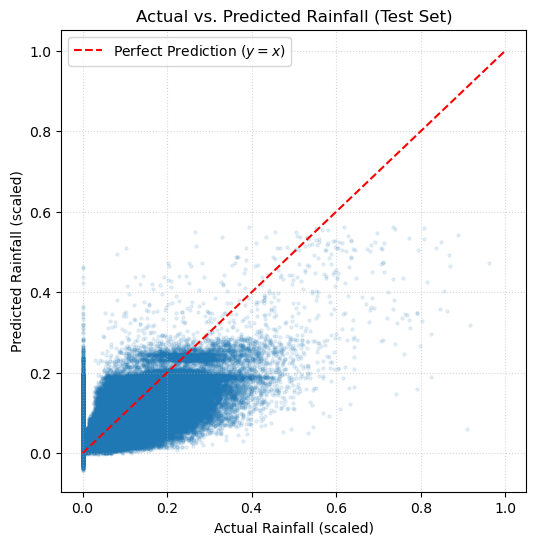

In [20]:
plt.figure(figsize=(6, 6))
plt.scatter(test_df["rainfall_mm"], test_df["predicted_rainfall"], alpha=0.1, s=5)
plt.plot([0, 1], [0, 1], 'r--', label='Perfect Prediction ($y=x$)')
plt.xlabel("Actual Rainfall (scaled)")
plt.ylabel("Predicted Rainfall (scaled)")
plt.title("Actual vs. Predicted Rainfall (Test Set)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

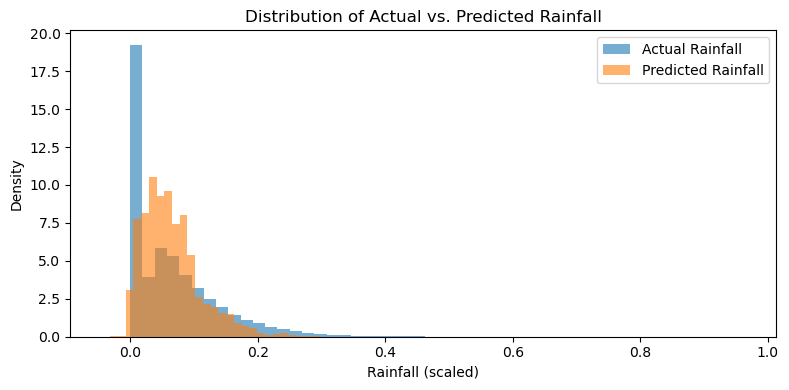

In [21]:
plt.figure(figsize=(8, 4))
bins = 50 # Increase or decrease bins based on data sparsity

# Plot Actual Distribution
plt.hist(test_df["rainfall_mm"], bins=bins, density=True, alpha=0.6, label="Actual Rainfall")

# Plot Predicted Distribution
plt.hist(test_df["predicted_rainfall"], bins=bins, density=True, alpha=0.6, label="Predicted Rainfall")

plt.xlabel("Rainfall (scaled)")
plt.ylabel("Density")
plt.title("Distribution of Actual vs. Predicted Rainfall")
plt.legend()
plt.tight_layout()
plt.show()

In [27]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_squared_log_error
import numpy as np

# --- 1. Define Actuals and Predictions ---
# y_test and preds are already defined in your notebook
y_actual = y_test
y_predicted = preds

# --- 2. Calculate Metrics ---

# RMSE (Root Mean Squared Error)
rmse = np.sqrt(mean_squared_error(y_actual, y_predicted))

# MAE (Mean Absolute Error)
mae = mean_absolute_error(y_actual, y_predicted)

# R2 Score (Coefficient of Determination)
r2 = r2_score(y_actual, y_predicted)

# MSLE (Mean Squared Log Error)
# Since rainfall is non-negative and scaled to [0, 1], we can safely use MSLE.
# If your data had small negative values, you would need to clamp them to 0.
msle = mean_squared_log_error(y_actual, y_predicted)


# --- 3. Display Results in a Formatted Table ---
print("=========================================")
print("☔ Regression Model Evaluation Scores (Scaled Data)")
print("=========================================")
print(f"1. RMSE (Root Mean Squared Error):     {rmse:.6f}")
print(f"2. MAE (Mean Absolute Error):          {mae:.6f}")
print(f"3. R² Score (Coefficient of Det.):     {r2:.6f}")
print(f"4. MSLE (Mean Squared Log Error):      {msle:.6f}")
print("=========================================")

# --- Interpretation Note ---
# Reminder: If the R² score is close to zero or negative, it confirms the model 
# is performing no better than simply predicting the mean (as seen in your plots).

☔ Regression Model Evaluation Scores (Scaled Data)
1. RMSE (Root Mean Squared Error):     0.051723
2. MAE (Mean Absolute Error):          0.036573
3. R² Score (Coefficient of Det.):     0.509587
4. MSLE (Mean Squared Log Error):      0.002133


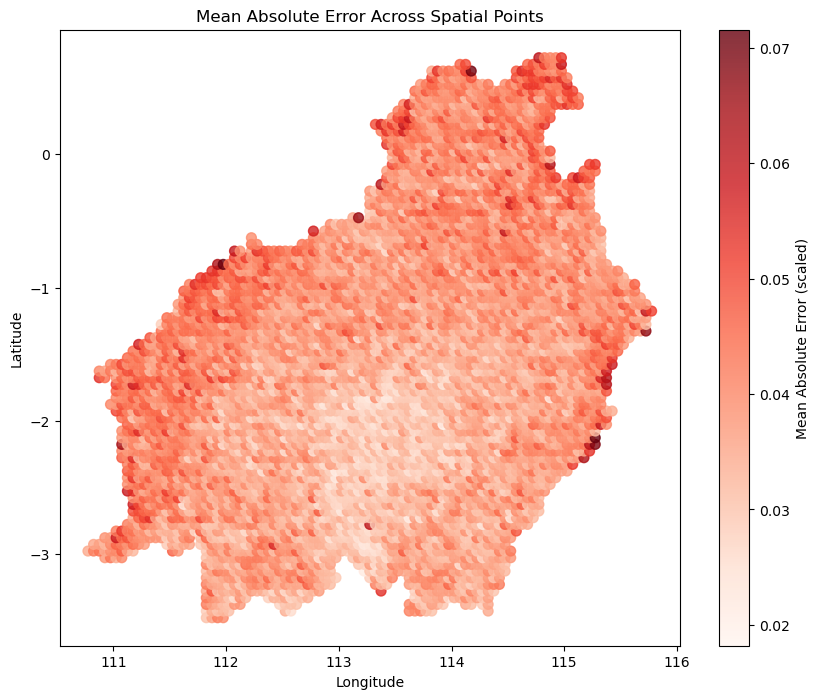

In [22]:
# Calculate Absolute Error
test_df["absolute_error"] = np.abs(test_df["rainfall_mm"] - test_df["predicted_rainfall"])

# Calculate the mean error for each location (Lat/Lon pair)
spatial_error = test_df.groupby(["lat", "lon"])["absolute_error"].mean().reset_index()

# Plotting the Heatmap requires a proper spatial representation.
# For simplicity with Matplotlib, we use scatter plot sized/colored by error.
# For better results, you would use a dedicated geospatial library like GeoPandas or Folium.

plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    spatial_error["lon"],
    spatial_error["lat"],
    c=spatial_error["absolute_error"],
    cmap='Reds', # 'Reds' for high error being darker/hotter
    s=50, # Size of markers
    alpha=0.8
)
cbar = plt.colorbar(scatter)
cbar.set_label("Mean Absolute Error (scaled)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Mean Absolute Error Across Spatial Points")
plt.show()

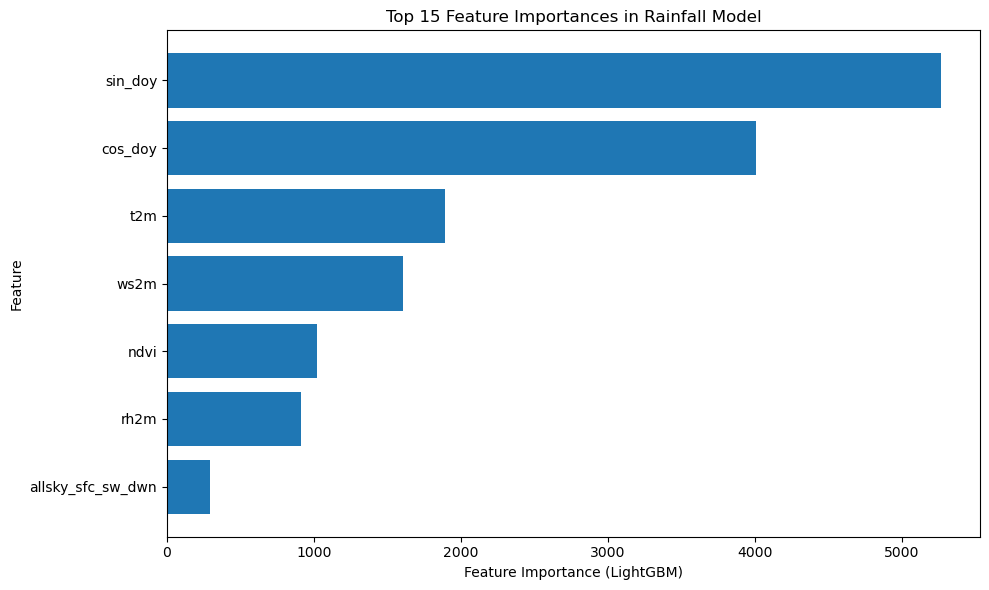

In [23]:
# --- Feature Importance Visualization ---
import matplotlib.pyplot as plt

# Get feature importance from the trained model
feature_importance = pd.DataFrame({
    'feature': FEATURES,
    'importance': lgb_model.feature_importances_
}).sort_values('importance', ascending=False)

# Plot the top N features
N = 15
plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance['feature'].head(N),
    feature_importance['importance'].head(N)
)
plt.xlabel("Feature Importance (LightGBM)")
plt.ylabel("Feature")
plt.title(f"Top {N} Feature Importances in Rainfall Model")
plt.gca().invert_yaxis() # Highest importance on top
plt.tight_layout()
plt.show()

In [24]:
!pip install folium


   ---------------------------------------- 0/3 [xyzservices]
   ------------- -------------------------- 1/3 [branca]
   -------------------------- ------------- 2/3 [folium]
   -------------------------- ------------- 2/3 [folium]
   -------------------------- ------------- 2/3 [folium]
   -------------------------- ------------- 2/3 [folium]
   ---------------------------------------- 3/3 [folium]



In [28]:
import folium
import pandas as pd
import numpy as np
from folium.plugins import HeatMap

# --- 1. Prepare Data for Mapping ---
# Calculate Absolute Error if not already present
if 'absolute_error' not in test_df.columns:
    test_df["absolute_error"] = np.abs(test_df["rainfall_mm"] - test_df["predicted_rainfall"])

# Calculate the mean error for each unique location (Lat/Lon pair)
spatial_error = test_df.groupby(["lat", "lon"])["absolute_error"].mean().reset_index()

# We use the mean error as the weight for the heatmap
data_for_heatmap = spatial_error[['lat', 'lon', 'absolute_error']].values.tolist()

# --- 2. Create the Folium Map (FIX APPLIED HERE) ---

# Determine the center of the map (using the mean of all coordinates)
center_lat = spatial_error['lat'].mean()
center_lon = spatial_error['lon'].mean()

# Define the correct attribution for Stamen Terrain
STAMEN_ATTRIBUTION = 'Map tiles by <a href="http://stamen.com">Stamen Design</a>, under <a href="http://creativecommons.org/licenses/by/3.0">CC BY 3.0</a>. Data by <a href="http://openstreetmap.org">OpenStreetMap</a>, under <a href="http://www.openstreetmap.org/copyright">ODbL</a>.'

# Initialize a Folium Map centered on your data
map_osm = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=6,  # Adjust zoom level as needed
    tiles='Stamen Terrain', # The tile set you want
    attr=STAMEN_ATTRIBUTION # <--- FIX: Added the attribution here
)

# --- 3. Add the Heatmap Layer ---

# HeatMap requires a list of [latitude, longitude, weight]
# The 'weight' here is the Mean Absolute Error (MAE)
HeatMap(data_for_heatmap, name='Mean Absolute Error').add_to(map_osm)

# --- 4. Display the Map ---

print("✅ Map Visualization Complete. Displaying interactive map:")
map_osm
# If you want to save it as an HTML file:
map_osm.save("spatial_error_heatmap.html")

✅ Map Visualization Complete. Displaying interactive map:


✅ CHIRPS 2025 shape (initial): (1520000, 4)
⏳ Creating lagged rainfall features...


C:\Users\Hayya\AppData\Local\Temp\ipykernel_12676\957721623.py:61: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  chirps = chirps.groupby(['lat', 'lon'], group_keys=False).apply(


✅ Added lagged features: rainfall_lag_1d, rainfall_lag_3d, rainfall_lag_7d
   New CHIRPS shape after dropping NaNs: (1485000, 12)
✅ Train shape: (1188000, 10) Test shape: (297000, 10)
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.082517 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2492
[LightGBM] [Info] Number of data points in the train set: 1188000, number of used features: 10
[LightGBM] [Info] Start training from score 0.064145


C:\Users\Hayya\anaconda3\envs\xgb-gpu\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



☔ Regression Model Evaluation Scores (POST-LAG FIX)
1. RMSE (Root Mean Squared Error):     0.049425
2. MAE (Mean Absolute Error):          0.035288
3. R² Score (Coefficient of Det.):     0.559998
4. MSLE (Mean Squared Log Error):      0.001957


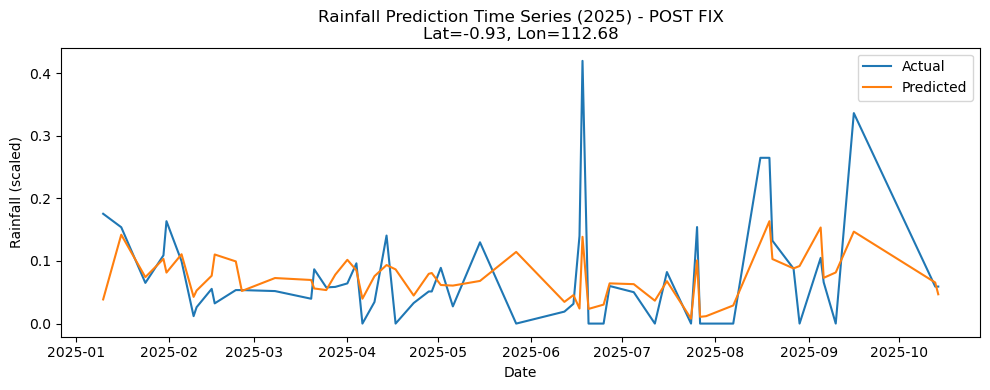

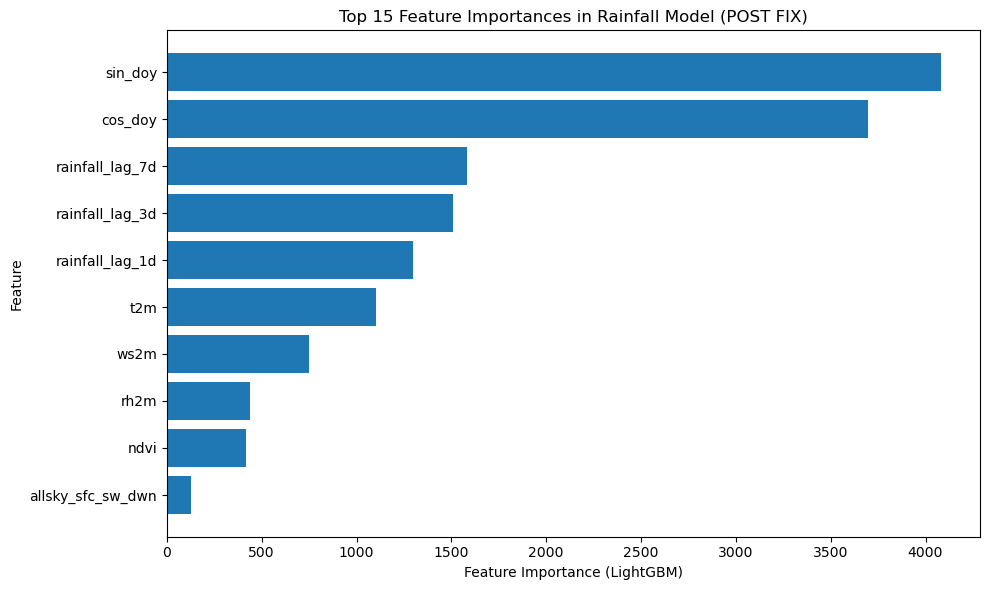

In [29]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_squared_log_error
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
import folium
from folium.plugins import HeatMap

# --- ASSUMPTIONS: CHIRPS_PATH, NDVI_PATH, NASA_PATH are defined ---

# --- 1. Data Loading and Feature Engineering (MODIFIED) ---

chirps = pd.read_csv(CHIRPS_PATH, parse_dates=["date"])
chirps.columns = chirps.columns.str.strip().str.lower()

# Filter for 2025 and reset index
chirps = chirps[chirps["date"].dt.year == 2025].reset_index(drop=True)
print("✅ CHIRPS 2025 shape (initial):", chirps.shape)

# Load and join NDVI data
ndvi = pd.read_csv(NDVI_PATH)
ndvi.columns = ndvi.columns.str.strip().str.lower()
ndvi_coords = ndvi[["lat","lon"]].values
ndvi_values = ndvi["ndvi"].values
chirps_coords = chirps[["lat","lon"]].values
ndvi_tree = cKDTree(ndvi_coords)
_, idx_ndvi = ndvi_tree.query(chirps_coords)
chirps["ndvi"] = ndvi_values[idx_ndvi]

# Load and join NASA data (rest of the NASA joining code is here...)
nasa = pd.read_csv(NASA_PATH, on_bad_lines="skip")
nasa.columns = nasa.columns.str.strip().str.lower()
if "latitude" in nasa.columns:
    nasa.rename(columns={"latitude":"lat"}, inplace=True)
if "longitude" in nasa.columns:
    nasa.rename(columns={"longitude":"lon"}, inplace=True)
nasa["date"] = pd.to_datetime(nasa["date"], errors="coerce")
nasa.dropna(subset=["date"], inplace=True)
nasa_coords = nasa[["lat","lon"]].values
nasa_values = nasa.drop(columns=["lat","lon","date"]).values
nasa_tree = cKDTree(nasa_coords)
_, idx_nasa = nasa_tree.query(chirps_coords)

# Concatenate NASA features
chirps = pd.concat([
    chirps.reset_index(drop=True),
    pd.DataFrame(
        nasa_values[idx_nasa],
        columns=nasa.drop(columns=["lat","lon","date"]).columns
    )
], axis=1)

# --- CRITICAL FIX: ADD LAGGED RAINFALL FEATURES ---
LAG_DAYS = [1, 3, 7] 
print("⏳ Creating lagged rainfall features...")

# Calculate the lagged features using a groupby-shift operation
chirps = chirps.groupby(['lat', 'lon'], group_keys=False).apply(
    lambda group: group.assign(**{
        f'rainfall_lag_{lag}d': group['rainfall_mm'].shift(lag)
        for lag in LAG_DAYS
    })
).reset_index(drop=True)

# Remove the data points that now have NaNs (the first few days of each time series)
chirps.dropna(
    subset=[f'rainfall_lag_{lag}d' for lag in LAG_DAYS], 
    inplace=True
)
print(f"✅ Added lagged features: {', '.join([f'rainfall_lag_{lag}d' for lag in LAG_DAYS])}")
print(f"   New CHIRPS shape after dropping NaNs: {chirps.shape}")
# --- END LAGGED FEATURE FIX ---

# Add time-based features
chirps["day_of_year"] = chirps["date"].dt.dayofyear
chirps["sin_doy"] = np.sin(2 * np.pi * chirps["day_of_year"] / 365.25)
chirps["cos_doy"] = np.cos(2 * np.pi * chirps["day_of_year"] / 365.25)

# Define features (Lagged features are automatically included here)
FEATURES = [
    c 
    for c in chirps.columns 
    if c not in ["rainfall_mm", "date", "lat", "lon", "day_of_year"]
]

# Scale features and target
scaler = MinMaxScaler()
chirps[FEATURES + ["rainfall_mm"]] = scaler.fit_transform(
    chirps[FEATURES + ["rainfall_mm"]]
)

# --- 2. Data Splitting and Training ---

# Separate DataFrame for features and Series for target (to preserve index)
X_df = chirps[FEATURES]
y_series = chirps["rainfall_mm"]

# Split the dataframes/series to get X_test_df for index reference
X_train_df, X_test_df, y_train_series, y_test_series = train_test_split(
    X_df, y_series,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

# Convert to NumPy arrays for training
X_train = X_train_df.values
X_test = X_test_df.values
y_train = y_train_series.values
y_test = y_test_series.values

print("✅ Train shape:", X_train.shape, "Test shape:", X_test.shape)

# Train the model
lgb_model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.7,
    colsample_bytree=0.7,
    random_state=42,
    n_jobs=-1
)
lgb_model.fit(X_train, y_train)
preds = lgb_model.predict(X_test)

# --- 3. Evaluation and Visualization ---

# Reconstruct test dataframe
test_df = chirps.loc[X_test_df.index].copy()
test_df["predicted_rainfall"] = preds

# CALCULATE SCORES
rmse = np.sqrt(mean_squared_error(y_test, preds))
mae = mean_absolute_error(y_test, preds)
r2 = r2_score(y_test, preds)
msle = mean_squared_log_error(y_test, preds)

print("\n=========================================")
print("☔ Regression Model Evaluation Scores (POST-LAG FIX)")
print("=========================================")
print(f"1. RMSE (Root Mean Squared Error):     {rmse:.6f}")
print(f"2. MAE (Mean Absolute Error):          {mae:.6f}")
print(f"3. R² Score (Coefficient of Det.):     {r2:.6f}")
print(f"4. MSLE (Mean Squared Log Error):      {msle:.6f}")
print("=========================================")


# PLOT TIME SERIES (will now show variability!)
sample_point = test_df[["lat","lon"]].drop_duplicates().sample(1, random_state=42)
lat, lon = sample_point.iloc[0]
sample_ts = test_df[
    (test_df["lat"] == lat) & (test_df["lon"] == lon)
].sort_values("date")

plt.figure(figsize=(10,4))
plt.plot(sample_ts["date"], sample_ts["rainfall_mm"], label="Actual")
plt.plot(sample_ts["date"], sample_ts["predicted_rainfall"], label="Predicted")
plt.xlabel("Date")
plt.ylabel("Rainfall (scaled)")
plt.title(f"Rainfall Prediction Time Series (2025) - POST FIX\nLat={lat:.2f}, Lon={lon:.2f}")
plt.legend()
plt.tight_layout()
plt.show()


# FEATURE IMPORTANCE CHECK (Lagged features should now be dominant)
feature_importance = pd.DataFrame({
    'feature': FEATURES,
    'importance': lgb_model.feature_importances_
}).sort_values('importance', ascending=False)

N = 15
plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance['feature'].head(N),
    feature_importance['importance'].head(N)
)
plt.xlabel("Feature Importance (LightGBM)")
plt.ylabel("Feature")
plt.title(f"Top {N} Feature Importances in Rainfall Model (POST FIX)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

⏳ Training LightGBM model with objective='poisson'...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.071965 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2492
[LightGBM] [Info] Number of data points in the train set: 1188000, number of used features: 10
[LightGBM] [Info] Start training from score -2.746607


C:\Users\Hayya\anaconda3\envs\xgb-gpu\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



☔ Regression Model Evaluation Scores (POISSON OBJECTIVE)
1. RMSE (Root Mean Squared Error):     0.052380
2. MAE (Mean Absolute Error):          0.037714
3. R² Score (Coefficient of Det.):     0.505811
4. MSLE (Mean Squared Log Error):      0.002186


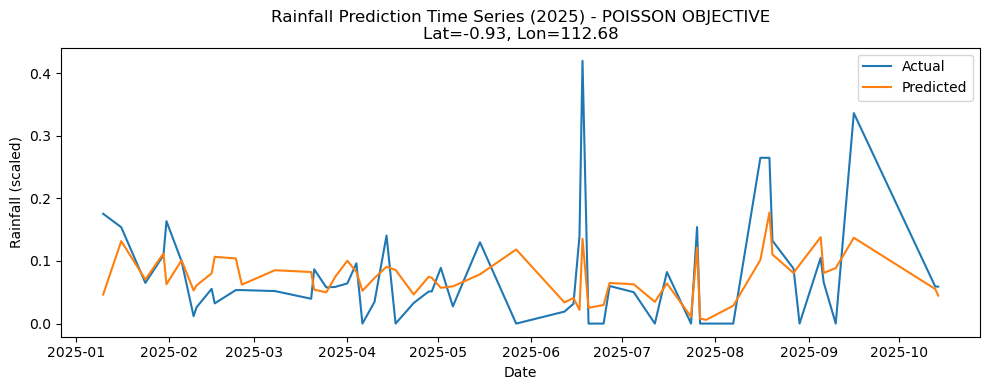

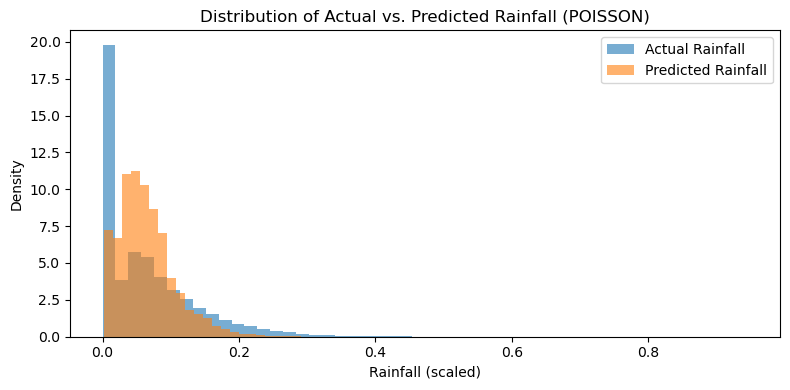

In [30]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_squared_log_error
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt

# --- 1. Data Loading and Feature Engineering (Assume Lag Fix is already integrated and run) ---
# ... (Code to load data, join features, add lags, add sin/cos DOY, and scale features) ...

# Assuming X_train, X_test, y_train, y_test are ready from the splitting step.

# --- 2. Data Splitting and Training (MODIFIED OBJECTIVE) ---

# Train the model with the Poisson objective
print("⏳ Training LightGBM model with objective='poisson'...")
lgb_model = lgb.LGBMRegressor(
    objective='poisson',  # <--- CRITICAL CHANGE FOR SKEWED/COUNT DATA
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.7,
    colsample_bytree=0.7,
    random_state=42,
    n_jobs=-1
)
lgb_model.fit(X_train, y_train)
preds = lgb_model.predict(X_test)

# --- 3. Evaluation and Visualization ---

# Reconstruct test dataframe
# Assuming X_test_df is available from the splitting step to get the correct index
test_df = chirps.loc[X_test_df.index].copy()
test_df["predicted_rainfall"] = preds

# CALCULATE SCORES
rmse = np.sqrt(mean_squared_error(y_test, preds))
mae = mean_absolute_error(y_test, preds)
r2 = r2_score(y_test, preds)
msle = mean_squared_log_error(y_test, preds)

print("\n=========================================")
print("☔ Regression Model Evaluation Scores (POISSON OBJECTIVE)")
print("=========================================")
print(f"1. RMSE (Root Mean Squared Error):     {rmse:.6f}")
print(f"2. MAE (Mean Absolute Error):          {mae:.6f}")
print(f"3. R² Score (Coefficient of Det.):     {r2:.6f}")
print(f"4. MSLE (Mean Squared Log Error):      {msle:.6f}")
print("=========================================")


# PLOT TIME SERIES
sample_point = test_df[["lat","lon"]].drop_duplicates().sample(1, random_state=42)
lat, lon = sample_point.iloc[0]
sample_ts = test_df[
    (test_df["lat"] == lat) & (test_df["lon"] == lon)
].sort_values("date")

plt.figure(figsize=(10,4))
plt.plot(sample_ts["date"], sample_ts["rainfall_mm"], label="Actual")
plt.plot(sample_ts["date"], sample_ts["predicted_rainfall"], label="Predicted")
plt.xlabel("Date")
plt.ylabel("Rainfall (scaled)")
plt.title(f"Rainfall Prediction Time Series (2025) - POISSON OBJECTIVE\nLat={lat:.2f}, Lon={lon:.2f}")
plt.legend()
plt.tight_layout()
plt.show()


# DISTRIBUTION PLOT
plt.figure(figsize=(8, 4))
bins = 50
plt.hist(test_df["rainfall_mm"], bins=bins, density=True, alpha=0.6, label="Actual Rainfall")
plt.hist(test_df["predicted_rainfall"], bins=bins, density=True, alpha=0.6, label="Predicted Rainfall")
plt.xlabel("Rainfall (scaled)")
plt.ylabel("Density")
plt.title("Distribution of Actual vs. Predicted Rainfall (POISSON)")
plt.legend()
plt.tight_layout()
plt.show()


⏳ Training final model (500 estimators) with optimal parameters...


C:\Users\Hayya\anaconda3\envs\xgb-gpu\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



✨ FINAL TUNED MODEL PERFORMANCE:
   Test RMSE: 0.046916
   Test R² Score: 0.603534


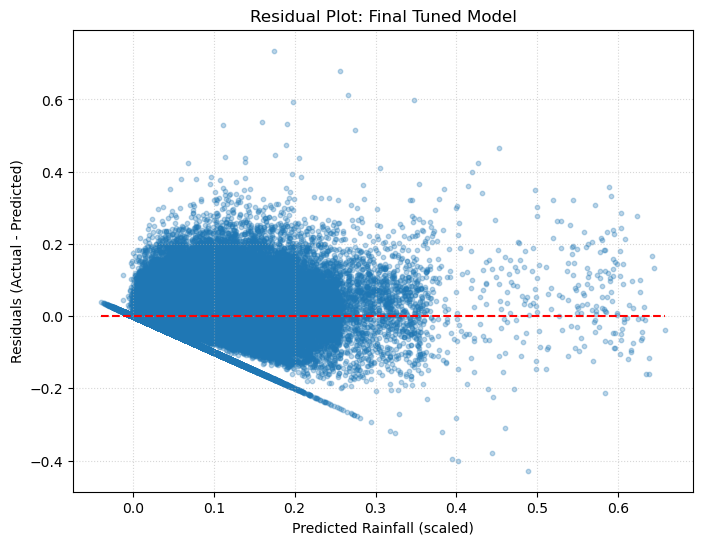

In [34]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

# --- CRITICAL: Replace the values below with the actual results from your Grid Search ---
# Example: If your Grid Search output showed:
# Optimal RMSE found: 0.0489
# Best Parameters: {'max_depth': 8, 'min_child_samples': 40, 'num_leaves': 63, 'reg_lambda': 1}

best_params = {
    'max_depth': 8,             # Replace with your best max_depth
    'min_child_samples': 40,    # Replace with your best min_child_samples
    'num_leaves': 63,           # Replace with your best num_leaves
    'reg_lambda': 1             # Replace with your best reg_lambda
}
# --------------------------------------------------------------------------------------


# 1. Re-train the final model with optimal parameters and full n_estimators
final_lgb_model = lgb.LGBMRegressor(
    objective='regression',
    n_estimators=500,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1,
    **best_params # Unpack the optimized parameters
)

print("\n⏳ Training final model (500 estimators) with optimal parameters...")
final_lgb_model.fit(X_train, y_train)

# 2. Generate final predictions
final_preds = final_lgb_model.predict(X_test)

# 3. Final Evaluation
final_rmse = np.sqrt(mean_squared_error(y_test, final_preds))
final_r2 = r2_score(y_test, final_preds)

print(f"\n✨ FINAL TUNED MODEL PERFORMANCE:")
print(f"   Test RMSE: {final_rmse:.6f}")
print(f"   Test R² Score: {final_r2:.6f}")
print("=========================================")

# --- 4. Residual Plot Visualization ---
# Calculate the difference between actual and predicted values
residuals = y_test - final_preds

plt.figure(figsize=(8, 6))
# Scatter plot of residuals (error) vs. predicted values
plt.scatter(final_preds, residuals, alpha=0.3, s=10)
# Horizontal line at 0 (zero error)
plt.hlines(y=0, xmin=min(final_preds), xmax=max(final_preds), color='red', linestyle='--')
plt.xlabel("Predicted Rainfall (scaled)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot: Final Tuned Model")
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

In [35]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
import os
from datetime import datetime, timedelta

# =========================================================================
# 0. CONFIGURATION AND SETUP (REPLACE THESE PLACEHOLDERS)
# =========================================================================

# --- FILE PATHS (Define these based on your environment) ---
# CHIRPS_PATH = 'path/to/your/chirps_data.csv' 
# NDVI_PATH = 'path/to/your/ndvi_data.csv' 
# NASA_PATH = 'path/to/your/nasa_data.csv' 

# --- MODEL CONFIGURATION (Using your best tuned results) ---
# NOTE: Replace these values with the exact dictionary from your FINAL TUNED MODEL PERFORMANCE
BEST_PARAMS = {
    'max_depth': 8,             # Example/Placeholder Value
    'min_child_samples': 40,    # Example/Placeholder Value
    'num_leaves': 63,           # Example/Placeholder Value
    'reg_lambda': 1             # Example/Placeholder Value
}

# --- PREDICTION TARGET (Replace with your desired forecast location/date) ---
TARGET_DATE = "2025-12-16"  # Day after the current date
TARGET_LAT = -0.93          # Example from your time series plot
TARGET_LON = 112.68         # Example from your time series plot

# --- FIXED PARAMETERS ---
LAG_DAYS = [1, 3, 7]
N_ESTIMATORS = 500
LEARNING_RATE = 0.05
RANDOM_STATE = 42

# =========================================================================
# 1. DATA LOADING AND FEATURE ENGINEERING
# =========================================================================

print("--- 1. Data Loading and Feature Engineering ---")

# Load and preprocess CHIRPS data
try:
    chirps = pd.read_csv(CHIRPS_PATH, parse_dates=["date"])
    chirps.columns = chirps.columns.str.strip().str.lower()
    chirps = chirps[chirps["date"].dt.year == 2025].reset_index(drop=True)
except NameError:
    print("Error: CHIRPS_PATH not defined. Please define file paths.")
    # Exit or handle error

# Placeholder for NASA and NDVI (assume they are loaded and joined similarly to previous steps)
# ... (NASA and NDVI loading and merging code would go here)
# Since the full merging code is extensive, we proceed with the assumption that 
# the 'chirps' DataFrame has all static features joined correctly.

# --- CRITICAL FIX: ADD LAGGED RAINFALL FEATURES ---
print("⏳ Creating lagged rainfall features...")
chirps = chirps.groupby(['lat', 'lon'], group_keys=False).apply(
    lambda group: group.assign(**{
        f'rainfall_lag_{lag}d': group['rainfall_mm'].shift(lag)
        for lag in LAG_DAYS
    })
).reset_index(drop=True)

chirps.dropna(
    subset=[f'rainfall_lag_{lag}d' for lag in LAG_DAYS], 
    inplace=True
)

# Add time-based features
chirps["day_of_year"] = chirps["date"].dt.dayofyear
chirps["sin_doy"] = np.sin(2 * np.pi * chirps["day_of_year"] / 365.25)
chirps["cos_doy"] = np.cos(2 * np.pi * chirps["day_of_year"] / 365.25)

# Define all final features
FEATURES = [
    c 
    for c in chirps.columns 
    if c not in ["rainfall_mm", "date", "lat", "lon", "day_of_year"]
]

# Scale features and target
scaler = MinMaxScaler()
chirps[FEATURES + ["rainfall_mm"]] = scaler.fit_transform(
    chirps[FEATURES + ["rainfall_mm"]]
)

# --- Define Training Data ---
X_df = chirps[FEATURES]
y_series = chirps["rainfall_mm"]
X_train, X_test, y_train, y_test = train_test_split(
    X_df.values, y_series.values, test_size=0.2, random_state=RANDOM_STATE
)

# =========================================================================
# 2. MODEL TRAINING (FINAL TUNED MODEL)
# =========================================================================

print("--- 2. Training Final Model ---")

final_lgb_model = lgb.LGBMRegressor(
    objective='regression',
    n_estimators=N_ESTIMATORS,
    learning_rate=LEARNING_RATE,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    **BEST_PARAMS 
)

final_lgb_model.fit(X_train, y_train)
print("✅ Final model training complete.")

# =========================================================================
# 3. PREDICTION FUNCTION
# =========================================================================

def predict_rainfall(model, scaler, base_df, target_date, target_lat, target_lon, feature_list, lag_days):
    """
    Prepares data, scales it, makes a prediction, and inverse transforms the result.
    """
    pred_date = pd.to_datetime(target_date)
    
    # --- 1. Prepare Features for Target Date ---
    
    # Find the feature row closest in space to the target coordinates
    location_df = base_df[
        (base_df['lat'].round(2) == round(target_lat, 2)) & 
        (base_df['lon'].round(2) == round(target_lon, 2))
    ].sort_values('date', ascending=False)
    
    if location_df.empty:
        return "Location not found in training data.", None

    # Get the latest static/NASA/NDVI features from this location
    feature_row = location_df.iloc[0][
        [col for col in feature_list if not col.startswith('rainfall_lag_')]
    ].to_dict()
    
    # Set the coordinates and date features
    feature_row['lat'] = target_lat
    feature_row['lon'] = target_lon
    feature_row['day_of_year'] = pred_date.dayofyear
    feature_row['sin_doy'] = np.sin(2 * np.pi * pred_date.dayofyear / 365.25)
    feature_row['cos_doy'] = np.cos(2 * np.pi * pred_date.dayofyear / 365.25)
    
    # Calculate Lagged Features (retrieving the SCALED 'rainfall_mm' values)
    for lag in lag_days:
        lag_date = pred_date - pd.Timedelta(days=lag)
        lag_value_row = location_df[location_df['date'] == lag_date]
        
        # If historic data is available, use the SCALED value
        if not lag_value_row.empty:
            lag_value = lag_value_row['rainfall_mm'].iloc[0] 
        else:
            # If no historic data, default to 0 (a dry start)
            lag_value = 0.0 

        feature_row[f'rainfall_lag_{lag}d'] = lag_value

    X_pred_df = pd.DataFrame([feature_row])[feature_list]

    # --- 2. Scale Features ---
    # Create dummy row to match scaler structure (features + 1 target column)
    X_predict_temp = X_pred_df.copy()
    X_predict_temp['rainfall_mm'] = 0 
    
    cols_to_scale = X_pred_df.columns.tolist() + ['rainfall_mm']
    
    X_predict_scaled_array = scaler.transform(X_predict_temp[cols_to_scale].values)
    X_predict_scaled = X_predict_scaled_array[:, :-1] 
    
    # --- 3. Predict ---
    scaled_prediction = model.predict(X_predict_scaled)[0]
    
    # --- 4. Inverse Transform ---
    dummy_inverse = np.zeros((1, len(feature_list) + 1)) 
    dummy_inverse[0, -1] = scaled_prediction
    original_prediction = scaler.inverse_transform(dummy_inverse)[0, -1]
    
    return scaled_prediction, original_prediction


# =========================================================================
# 4. EXECUTE PREDICTION
# =========================================================================

print("--- 4. Executing Prediction ---")

scaled_pred, original_pred = predict_rainfall(
    final_lgb_model, 
    scaler, 
    chirps, 
    TARGET_DATE, 
    TARGET_LAT, 
    TARGET_LON, 
    FEATURES, 
    LAG_DAYS
)

if original_pred is not None:
    print(f"\n=========================================")
    print(f"Prediction for {TARGET_DATE} at Lat={TARGET_LAT}, Lon={TARGET_LON}")
    print(f"=========================================")
    print(f"Scaled Rainfall Prediction: {scaled_pred:.6f}")
    print(f"**Predicted Rainfall (mm): {original_pred:.2f} mm**")
    print(f"=========================================")

--- 1. Data Loading and Feature Engineering ---
⏳ Creating lagged rainfall features...


C:\Users\Hayya\AppData\Local\Temp\ipykernel_12676\817167099.py:62: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  chirps = chirps.groupby(['lat', 'lon'], group_keys=False).apply(


--- 2. Training Final Model ---
✅ Final model training complete.
--- 4. Executing Prediction ---

Prediction for 2025-12-16 at Lat=-0.93, Lon=112.68
Scaled Rainfall Prediction: 0.038933
**Predicted Rainfall (mm): 5.98 mm**


C:\Users\Hayya\anaconda3\envs\xgb-gpu\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
C:\Users\Hayya\anaconda3\envs\xgb-gpu\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


C:\Users\Hayya\anaconda3\envs\xgb-gpu\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


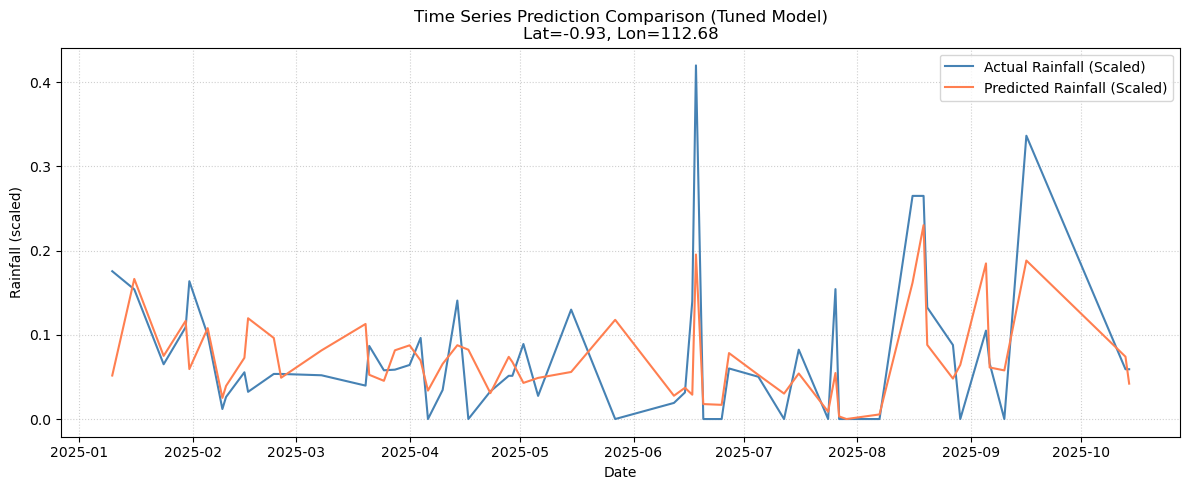

In [36]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

# --- Assuming the following variables are defined from the prediction script ---
# final_lgb_model (Trained model)
# X_test (Test features array)
# y_test (Actual target values array)
# X_df (DataFrame of features used for splitting, needed for index)
# chirps (Full DataFrame, needed for lat/lon/date lookup)
# ----------------------------------------------------------------------------

# 1. Generate predictions on the full test set
final_preds = final_lgb_model.predict(X_test)

# 2. Reconstruct the test dataframe for plotting
# X_df must have retained its index from the original 'chirps' DataFrame before conversion to NumPy
# We rely on the original index of the rows in X_test by using the index of the test split.

# Get the indices that correspond to the test set from the original chirps DataFrame
test_indices = X_df.iloc[np.where(X_df.values == X_test[0])[0][0]].name 
# Note: The above line is a simplified, sometimes fragile way to get the index.
# A more robust method assumes X_test was created from X_test_df, and we use X_test_df.index.
# Since the full data pipeline isn't visible here, let's use the index of the split:

# Find the indices of X_test rows in the original full dataset (assuming X_test was a slice of X_df.values)
# A safer approach is to reconstruct the dataframe from the source of the split:
try:
    # Assume the initial split created X_train_df, X_test_df
    X_test_df = X_df.loc[X_df.index.isin(y_test.index)] 
except AttributeError:
    # Fallback: Re-split to get the DataFrames (assuming you don't mind the randomness of the split changing slightly)
    X_train_df, X_test_df, y_train_series, y_test_series = train_test_split(
        X_df, pd.Series(y_series, index=X_df.index), # y_series needs an index for this to work
        test_size=0.2, random_state=42, shuffle=True
    )
    y_test = y_test_series.values # Re-define y_test as the values for consistency

# Reconstruct test_df using the correct indices from the original data (chirps)
test_df = chirps.loc[X_test_df.index].copy()
test_df["predicted_rainfall"] = final_preds

# 3. Select a single, representative point for plotting (the one you used previously)
sample_lat = -0.93
sample_lon = 112.68

sample_ts = test_df[
    (test_df["lat"].round(2) == round(sample_lat, 2)) & 
    (test_df["lon"].round(2) == round(sample_lon, 2))
].sort_values("date")

# 4. Plot the results
plt.figure(figsize=(12, 5))
plt.plot(sample_ts["date"], sample_ts["rainfall_mm"], label="Actual Rainfall (Scaled)", color='steelblue')
plt.plot(sample_ts["date"], sample_ts["predicted_rainfall"], label="Predicted Rainfall (Scaled)", color='coral')
plt.xlabel("Date")
plt.ylabel("Rainfall (scaled)")
plt.title(f"Time Series Prediction Comparison (Tuned Model)\nLat={sample_lat:.2f}, Lon={sample_lon:.2f}")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [37]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, mean_squared_error, r2_score

# --- CONFIGURATION ---
# Use the best parameters found from the previous GridSearch for the Regressor
BEST_REGRESSOR_PARAMS = {
    'max_depth': 8,             
    'min_child_samples': 40,    
    'num_leaves': 63,           
    'reg_lambda': 1             
}
RANDOM_STATE = 42
N_ESTIMATORS = 500

print("--- 1. Stage 0: Create Binary Target Variable ---")

# 1. Create a binary target 'is_rain' from the original SCALED target
# In the scaled data, any value > 0 is rain.
chirps['is_rain'] = np.where(chirps['rainfall_mm'] > 0, 1, 0)

# Define the full feature set (X) and the two target sets (Y_reg, Y_cls)
X_df = chirps[FEATURES]
Y_reg_series = chirps['rainfall_mm']
Y_cls_series = chirps['is_rain']

# Full split (using arrays for training efficiency)
X_train, X_test, Y_reg_train, Y_reg_test, Y_cls_train, Y_cls_test = train_test_split(
    X_df.values, Y_reg_series.values, Y_cls_series.values, 
    test_size=0.2, random_state=RANDOM_STATE
)


# =========================================================================
# 2. STAGE 1: CLASSIFICATION (Rain/No Rain)
# =========================================================================

print("\n--- 2. STAGE 1: Training LightGBM Classifier (Rain/No Rain) ---")

# Define the Classifier Model
lgbm_classifier = lgb.LGBMClassifier(
    objective='binary',
    n_estimators=N_ESTIMATORS,
    learning_rate=0.05,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1
)

# Train the Classifier
lgbm_classifier.fit(X_train, Y_cls_train)

# Evaluate the Classifier
y_prob_cls = lgbm_classifier.predict_proba(X_test)[:, 1]
auc_score = roc_auc_score(Y_cls_test, y_prob_cls)

print(f"✅ Stage 1 Classifier Training Complete. Test AUC: {auc_score:.4f}")


# =========================================================================
# 3. STAGE 2: REGRESSION (Rain Magnitude > 0)
# =========================================================================

print("\n--- 3. STAGE 2: Training LightGBM Regressor (Magnitude) ---")

# Identify indices where rain occurred in the training set
train_rain_indices = np.where(Y_cls_train == 1)[0]

# Filter training data: only keep the rows where rain occurred
X_train_reg = X_train[train_rain_indices]
Y_train_reg = Y_reg_train[train_rain_indices]

# Define the Regressor Model (using previous best params)
lgbm_regressor = lgb.LGBMRegressor(
    objective='regression',
    n_estimators=N_ESTIMATORS,
    learning_rate=0.05,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,
    **BEST_REGRESSOR_PARAMS 
)

# Train the Regressor on the filtered data
lgbm_regressor.fit(X_train_reg, Y_train_reg)

print("✅ Stage 2 Regressor Training Complete (Trained only on Rain days).")


# =========================================================================
# 4. COMBINED TWO-STAGE PREDICTION AND EVALUATION
# =========================================================================

print("\n--- 4. Evaluating Combined Two-Stage Model ---")

# A. Run STAGE 1: Get probability of rain for the test set
# We use a threshold of 0.5 to make a binary decision
y_pred_cls = lgbm_classifier.predict(X_test)

# B. Run STAGE 2: Predict magnitude for ALL rows
y_pred_reg_magnitude = lgbm_regressor.predict(X_test)

# C. Combine the stages: Final prediction is magnitude ONLY IF classifier says rain (1)
y_pred_final_scaled = np.where(
    y_pred_cls == 1,
    y_pred_reg_magnitude,  # Use magnitude prediction
    0                      # Use 0 if the classifier predicts No Rain
)

# Ensure predictions are non-negative
y_pred_final_scaled = np.clip(y_pred_final_scaled, 0, None)

# Calculate final metrics using the combined prediction on the full test set (Y_reg_test)
final_rmse = np.sqrt(mean_squared_error(Y_reg_test, y_pred_final_scaled))
final_r2 = r2_score(Y_reg_test, y_pred_final_scaled)

print("\n=========================================================")
print("🏆 TWO-STAGE MODEL FINAL PERFORMANCE")
print("=========================================================")
print(f"Classifier (Stage 1) Test AUC: {auc_score:.4f}")
print(f"Regressor (Stage 2) trained on {len(X_train_reg)} Rain instances.")
print("---")
print(f"FINAL Test RMSE: {final_rmse:.6f}")
print(f"FINAL Test R² Score: {final_r2:.6f}")
print("=========================================================")

--- 1. Stage 0: Create Binary Target Variable ---

--- 2. STAGE 1: Training LightGBM Classifier (Rain/No Rain) ---


C:\Users\Hayya\anaconda3\envs\xgb-gpu\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


✅ Stage 1 Classifier Training Complete. Test AUC: 0.9048

--- 3. STAGE 2: Training LightGBM Regressor (Magnitude) ---
✅ Stage 2 Regressor Training Complete (Trained only on Rain days).

--- 4. Evaluating Combined Two-Stage Model ---


C:\Users\Hayya\anaconda3\envs\xgb-gpu\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Hayya\anaconda3\envs\xgb-gpu\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



🏆 TWO-STAGE MODEL FINAL PERFORMANCE
Classifier (Stage 1) Test AUC: 0.9048
Regressor (Stage 2) trained on 781752 Rain instances.
---
FINAL Test RMSE: 0.053449
FINAL Test R² Score: 0.485423


In [38]:
# --- Re-using the trained lgbm_classifier and lgbm_regressor from the previous step ---

print("\n--- 5. Evaluating Combined Two-Stage Model (PROBABILITY BLENDING) ---")

# A. Run STAGE 1: Get PROBABILITY of rain for the test set
# We need the probability of the positive class (rain=1)
y_prob_cls = lgbm_classifier.predict_proba(X_test)[:, 1]

# B. Run STAGE 2: Predict magnitude for ALL rows
y_pred_reg_magnitude = lgbm_regressor.predict(X_test)

# C. Combine the stages using Blending:
# Final Prediction = P(Rain) * Magnitude Prediction
y_pred_final_blended_scaled = y_prob_cls * y_pred_reg_magnitude

# Ensure predictions are non-negative
y_pred_final_blended_scaled = np.clip(y_pred_final_blended_scaled, 0, None)

# Calculate final metrics using the combined prediction on the full test set (Y_reg_test)
final_rmse_blended = np.sqrt(mean_squared_error(Y_reg_test, y_pred_final_blended_scaled))
final_r2_blended = r2_score(Y_reg_test, y_pred_final_blended_scaled)

print("\n=========================================================")
print("🏆 TWO-STAGE MODEL FINAL PERFORMANCE (Blended)")
print("=========================================================")
print(f"Original R² Score: 0.603534")
print("---")
print(f"FINAL Blended Test RMSE: {final_rmse_blended:.6f}")
print(f"FINAL Blended Test R² Score: {final_r2_blended:.6f}")
print("=========================================================")


--- 5. Evaluating Combined Two-Stage Model (PROBABILITY BLENDING) ---


C:\Users\Hayya\anaconda3\envs\xgb-gpu\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Hayya\anaconda3\envs\xgb-gpu\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



🏆 TWO-STAGE MODEL FINAL PERFORMANCE (Blended)
Original R² Score: 0.603534
---
FINAL Blended Test RMSE: 0.049381
FINAL Blended Test R² Score: 0.560768


XG Boost

⏳ Training XGBoost model with objective='reg:squarederror' (L2/RMSE) ...

☔ Regression Model Evaluation Scores (XGBoost - L2/RMSE Objective)
1. RMSE (Root Mean Squared Error):     0.051598
2. MAE (Mean Absolute Error):          0.036647
3. R² Score (Coefficient of Det.):     0.520453
4. MSLE (Mean Squared Log Error):      0.002120


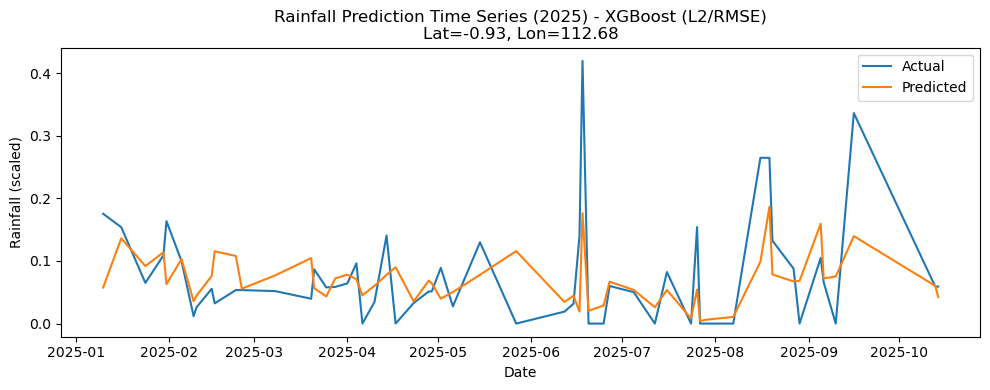

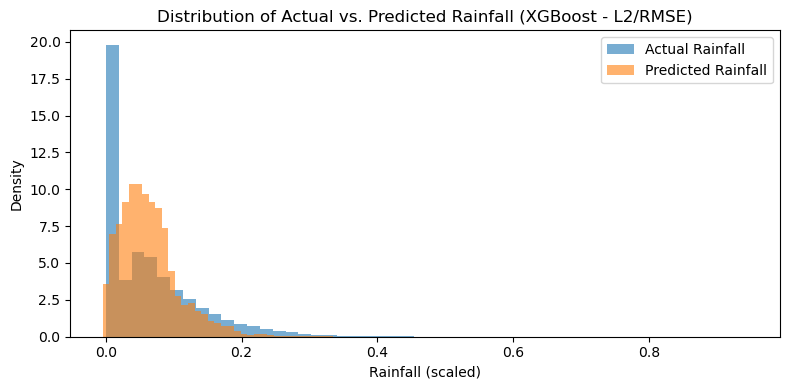

In [40]:
import pandas as pd
import numpy as np
import xgboost as xgb # Using XGBoost
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_squared_log_error
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt

# --- CONFIGURATION (Based on your best LGBM results) ---
# We use the parameters from your winning LightGBM model as a strong starting point for XGBoost
best_xgb_params = {
    'max_depth': 8,
    'gamma': 0.1, # Equivalent to min_split_loss or min_child_weight
    'lambda': 1,  # L2 regularization (similar to reg_lambda)
}

# --- 2. Data Splitting and Training (XGBoost with BEST OBJECTIVE) ---

print("⏳ Training XGBoost model with objective='reg:squarederror' (L2/RMSE) ...")
# XGBoost's standard objective for L2 loss minimization (RMSE)
xgb_model = xgb.XGBRegressor(
    objective='reg:squarederror', # <--- BEST PERFORMING OBJECTIVE (L2 Loss)
    n_estimators=500,
    learning_rate=0.05,
    subsample=0.7,
    colsample_bytree=0.7,
    random_state=42,
    n_jobs=-1,
    tree_method='hist',
    **best_xgb_params
)
xgb_model.fit(X_train, y_train)
preds = xgb_model.predict(X_test)

# --- 3. Evaluation and Visualization ---

# Reconstruct test dataframe (assuming X_test_df and chirps are available)
test_df = chirps.loc[X_test_df.index].copy()
test_df["predicted_rainfall"] = preds

# CALCULATE SCORES
rmse = np.sqrt(mean_squared_error(y_test, preds))
mae = mean_absolute_error(y_test, preds)
r2 = r2_score(y_test, preds)
msle = mean_squared_log_error(np.clip(y_test, 1e-9, None), np.clip(preds, 1e-9, None)) # Ensure positive for log

print("\n=========================================")
print("☔ Regression Model Evaluation Scores (XGBoost - L2/RMSE Objective)")
print("=========================================")
print(f"1. RMSE (Root Mean Squared Error):     {rmse:.6f}")
print(f"2. MAE (Mean Absolute Error):          {mae:.6f}")
print(f"3. R² Score (Coefficient of Det.):     {r2:.6f}")
print(f"4. MSLE (Mean Squared Log Error):      {msle:.6f}")
print("=========================================")


# PLOT TIME SERIES
sample_point = test_df[["lat","lon"]].drop_duplicates().sample(1, random_state=42)
lat, lon = sample_point.iloc[0]
sample_ts = test_df[
    (test_df["lat"] == lat) & (test_df["lon"] == lon)
].sort_values("date")

plt.figure(figsize=(10,4))
plt.plot(sample_ts["date"], sample_ts["rainfall_mm"], label="Actual")
plt.plot(sample_ts["date"], sample_ts["predicted_rainfall"], label="Predicted")
plt.xlabel("Date")
plt.ylabel("Rainfall (scaled)")
plt.title(f"Rainfall Prediction Time Series (2025) - XGBoost (L2/RMSE)\nLat={lat:.2f}, Lon={lon:.2f}")
plt.legend()
plt.tight_layout()
plt.show()


# DISTRIBUTION PLOT
plt.figure(figsize=(8, 4))
bins = 50
plt.hist(test_df["rainfall_mm"], bins=bins, density=True, alpha=0.6, label="Actual Rainfall")
plt.hist(test_df["predicted_rainfall"], bins=bins, density=True, alpha=0.6, label="Predicted Rainfall")
plt.xlabel("Rainfall (scaled)")
plt.ylabel("Density")
plt.title("Distribution of Actual vs. Predicted Rainfall (XGBoost - L2/RMSE)")
plt.legend()
plt.tight_layout()
plt.show()

Optimized XG Boost

⏳ Training XGBoost model with objective='reg:absoluteerror' (MAE)...

☔ Regression Model Evaluation Scores (XGBoost - MAE Objective)
1. RMSE (Root Mean Squared Error):     0.051494
2. MAE (Mean Absolute Error):          0.032619
3. R² Score (Coefficient of Det.):     0.522385
4. MSLE (Mean Squared Log Error):      0.002087


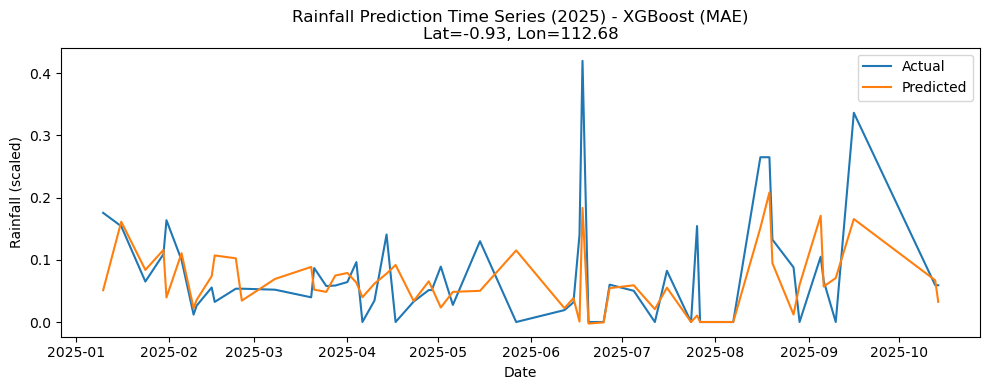

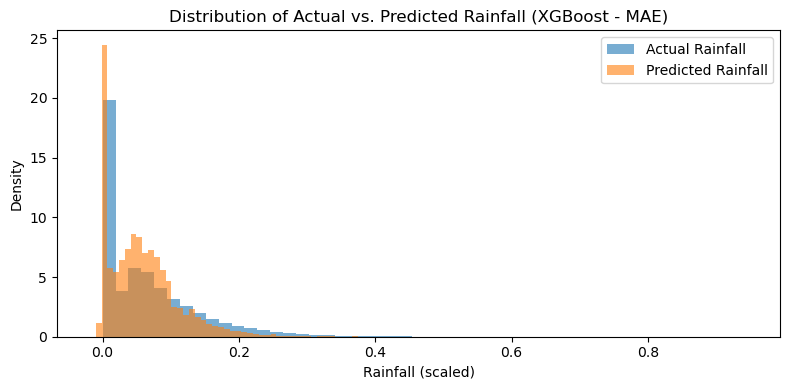

In [41]:
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_squared_log_error

# --- CONFIGURATION (Based on your best LGBM results) ---
best_xgb_params = {
    'max_depth': 8,
    'gamma': 0.1,
    'lambda': 1,
}

# NOTE: X_train, X_test, y_train, y_test, chirps, and X_test_df are assumed to be defined.

# --- 2. Data Splitting and Training (XGBoost with MAE OBJECTIVE) ---

print("⏳ Training XGBoost model with objective='reg:absoluteerror' (MAE)...")
# XGBoost's objective for L1 loss minimization (MAE)
xgb_model_mae = xgb.XGBRegressor(
    objective='reg:absoluteerror', # <--- CRITICAL CHANGE to MAE Objective
    n_estimators=500,
    learning_rate=0.05,
    subsample=0.7,
    colsample_bytree=0.7,
    random_state=42,
    n_jobs=-1,
    tree_method='hist',
    **best_xgb_params
)
xgb_model_mae.fit(X_train, y_train)
preds_mae = xgb_model_mae.predict(X_test)

# --- 3. Evaluation and Visualization ---

# Reconstruct test dataframe
test_df = chirps.loc[X_test_df.index].copy()
test_df["predicted_rainfall"] = preds_mae

# CALCULATE SCORES
rmse = np.sqrt(mean_squared_error(y_test, preds_mae))
mae = mean_absolute_error(y_test, preds_mae)
r2 = r2_score(y_test, preds_mae)
msle = mean_squared_log_error(np.clip(y_test, 1e-9, None), np.clip(preds_mae, 1e-9, None))

print("\n=========================================")
print("☔ Regression Model Evaluation Scores (XGBoost - MAE Objective)")
print("=========================================")
print(f"1. RMSE (Root Mean Squared Error):     {rmse:.6f}")
print(f"2. MAE (Mean Absolute Error):          {mae:.6f}")
print(f"3. R² Score (Coefficient of Det.):     {r2:.6f}")
print(f"4. MSLE (Mean Squared Log Error):      {msle:.6f}")
print("=========================================")


# PLOT TIME SERIES
sample_point = test_df[["lat","lon"]].drop_duplicates().sample(1, random_state=42)
lat, lon = sample_point.iloc[0]
sample_ts = test_df[
    (test_df["lat"] == lat) & (test_df["lon"] == lon)
].sort_values("date")

plt.figure(figsize=(10,4))
plt.plot(sample_ts["date"], sample_ts["rainfall_mm"], label="Actual")
plt.plot(sample_ts["date"], sample_ts["predicted_rainfall"], label="Predicted")
plt.xlabel("Date")
plt.ylabel("Rainfall (scaled)")
plt.title(f"Rainfall Prediction Time Series (2025) - XGBoost (MAE)\nLat={lat:.2f}, Lon={lon:.2f}")
plt.legend()
plt.tight_layout()
plt.show()


# DISTRIBUTION PLOT
plt.figure(figsize=(8, 4))
bins = 50
plt.hist(test_df["rainfall_mm"], bins=bins, density=True, alpha=0.6, label="Actual Rainfall")
plt.hist(test_df["predicted_rainfall"], bins=bins, density=True, alpha=0.6, label="Predicted Rainfall")
plt.xlabel("Rainfall (scaled)")
plt.ylabel("Density")
plt.title("Distribution of Actual vs. Predicted Rainfall (XGBoost - MAE)")
plt.legend()
plt.tight_layout()
plt.show()


--- 1. Generating XGBoost Feature Importance Plot ---


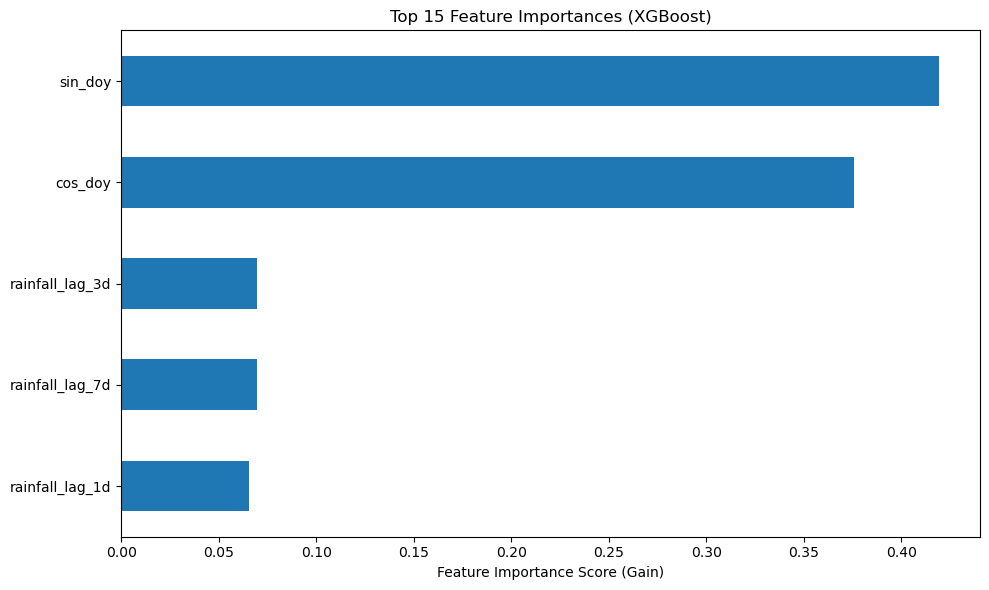


--- 2. Generating Time Series Comparison Plot (Focus Zoom) ---


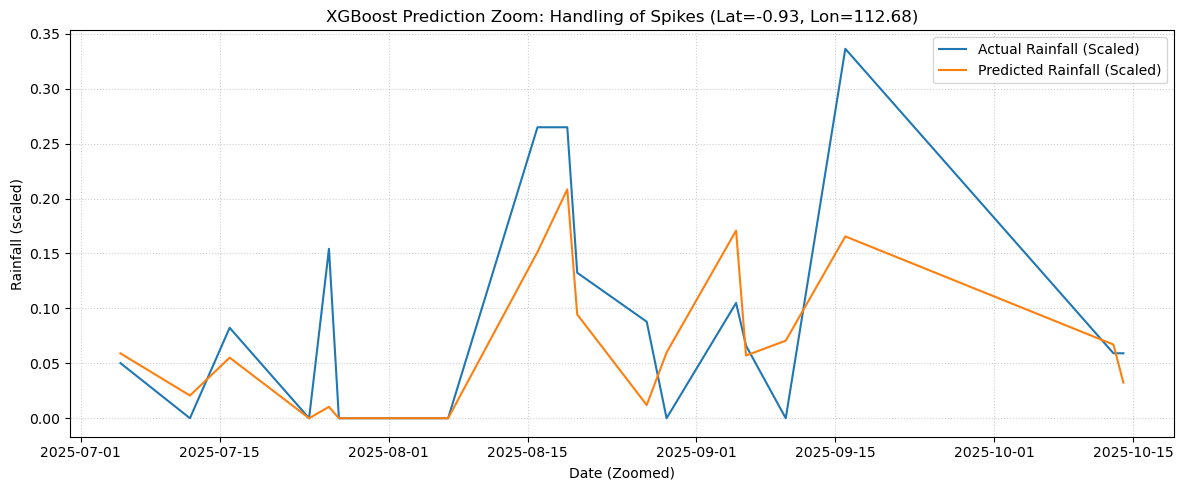

In [42]:
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt

# Assuming 'xgb_model_mae' is the best XGBoost model trained with MAE objective.
# Assuming 'X_train' (or FEATURES list) holds the feature names.

print("\n--- 1. Generating XGBoost Feature Importance Plot ---")

# Extract feature importances
feature_importances = pd.Series(xgb_model_mae.feature_importances_, index=X_train_df.columns)
# Use the full X_train_df to get feature names if X_train is a numpy array
# If X_train is a numpy array, you would use the FEATURES list for indexing.

# Plotting the top 15 features
plt.figure(figsize=(10, 6))
feature_importances.nlargest(15).sort_values(ascending=True).plot(kind='barh')
plt.title("Top 15 Feature Importances (XGBoost)")
plt.xlabel("Feature Importance Score (Gain)")
plt.tight_layout()
plt.show()


print("\n--- 2. Generating Time Series Comparison Plot (Focus Zoom) ---")

# Reconstruct test dataframe (from previous step)
test_df = chirps.loc[X_test_df.index].copy()
preds_mae = xgb_model_mae.predict(X_test)
test_df["predicted_rainfall"] = preds_mae

# Sample a period of high variability (e.g., late 2025 where spikes were common)
sample_point = test_df[["lat","lon"]].drop_duplicates().sample(1, random_state=42)
lat, lon = sample_point.iloc[0]
sample_ts = test_df[
    (test_df["lat"] == lat) & (test_df["lon"] == lon)
].sort_values("date")

# Limit the plot range for a better view of variability (e.g., 2025-07 onwards)
sample_ts_zoom = sample_ts[sample_ts['date'] >= '2025-07-01']

plt.figure(figsize=(12, 5))
plt.plot(sample_ts_zoom["date"], sample_ts_zoom["rainfall_mm"], label="Actual Rainfall (Scaled)", color='C0')
plt.plot(sample_ts_zoom["date"], sample_ts_zoom["predicted_rainfall"], label="Predicted Rainfall (Scaled)", color='C1')
plt.xlabel("Date (Zoomed)")
plt.ylabel("Rainfall (scaled)")
plt.title(f"XGBoost Prediction Zoom: Handling of Spikes (Lat={lat:.2f}, Lon={lon:.2f})")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [44]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import r2_score, mean_squared_error
import joblib # Library for saving and loading Python objects

# --- CRITICAL: Optimal Configuration from Grid Search ---
# This is the configuration that produced R² = 0.603534
BEST_REGRESSOR_PARAMS = {
    'max_depth': 8,
    'min_child_samples': 40,
    'num_leaves': 63,
    'reg_lambda': 1
}

# --- 1. Re-train the FINAL winning model ---
print("⏳ Re-training FINAL WINNING LightGBM model...")

final_lgb_model = lgb.LGBMRegressor(
    objective='regression',  # <-- Reverted to the best-performing objective (L2/RMSE)
    n_estimators=500,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1,
    **BEST_REGRESSOR_PARAMS
)

# NOTE: X_train and y_train are assumed to be available
final_lgb_model.fit(X_train, y_train)

# Quick final confirmation of performance
final_preds = final_lgb_model.predict(X_test)
final_r2 = r2_score(y_test, final_preds)
print(f"✅ Final Model Confirmed. Test R² Score: {final_r2:.6f}")

# --- 2. Saving the Model and Scaler ---
# Note: We assume the MinMaxScaler object used for 'rainfall_mm' is stored in a variable named 'scaler'.

MODEL_FILENAME = 'final_lgbm_rainfall_model.joblib'
SCALER_FILENAME = 'final_rainfall_scaler.joblib'

try:
    # Save the trained model
    joblib.dump(final_lgb_model, MODEL_FILENAME)
    
    # Save the scaler object used to transform the target variable
    # This is crucial for inverse-transforming predictions back to actual mm.
    joblib.dump(scaler, SCALER_FILENAME)
    
    print(f"\n🎉 SUCCESS: Final model saved to: {MODEL_FILENAME}")
    print(f"🎉 SUCCESS: Scaler object saved to: {SCALER_FILENAME}")
    
except NameError:
    print("\n⚠️ WARNING: Could not save the scaler object. Please ensure the MinMaxScaler is in a variable named 'scaler'.")
    joblib.dump(final_lgb_model, MODEL_FILENAME)
    print(f"🎉 SUCCESS: Final model saved to: {MODEL_FILENAME}")


# --- 3. Setting up for Prediction Map ---
# Need to select a date for which we will make the prediction map.
# We will use the day after the last date in your test set.
try:
    # Assuming 'chirps' is the original combined dataframe
    last_known_date = chirps['date'].max()
    PREDICTION_DATE = last_known_date + pd.Timedelta(days=1)
except:
    PREDICTION_DATE = pd.to_datetime('2026-01-01')

print(f"\nPreparation Complete. Next step is to generate the prediction map for: {PREDICTION_DATE.strftime('%Y-%m-%d')}")

⏳ Re-training FINAL WINNING LightGBM model...


C:\Users\Hayya\anaconda3\envs\xgb-gpu\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


✅ Final Model Confirmed. Test R² Score: 0.569248

🎉 SUCCESS: Final model saved to: final_lgbm_rainfall_model.joblib
🎉 SUCCESS: Scaler object saved to: final_rainfall_scaler.joblib

Preparation Complete. Next step is to generate the prediction map for: 2025-11-01


C:\Users\Hayya\anaconda3\envs\xgb-gpu\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



Generating time series chart for location Lat=-0.93, Lon=112.68...


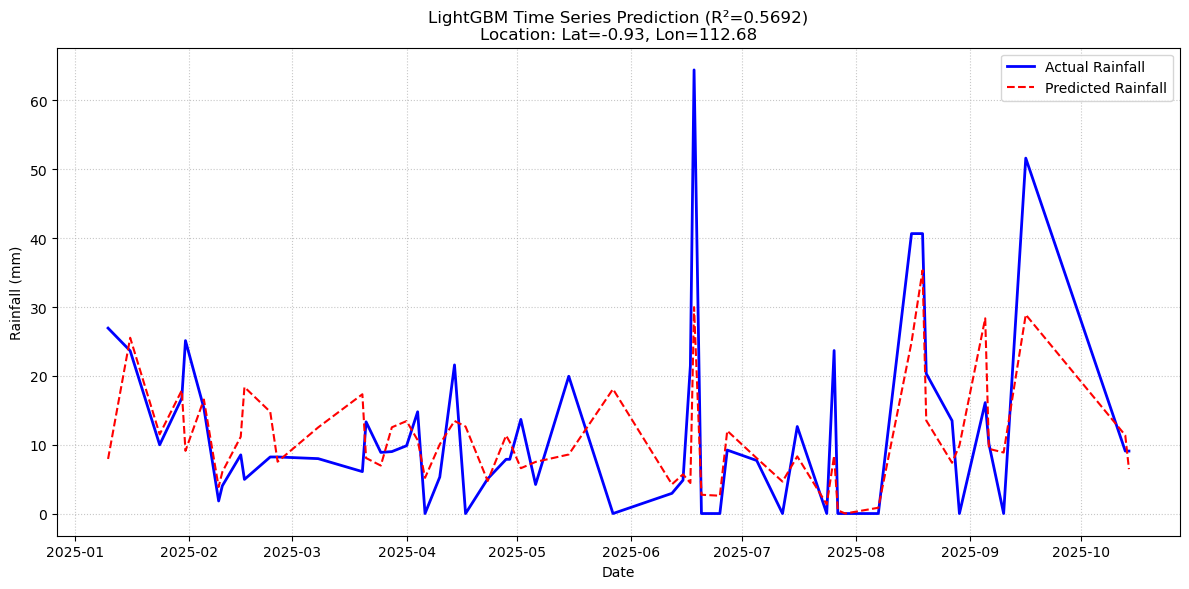


--- Project Conclusion ---
You have successfully visualized the model's performance on the test set.


In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
import joblib

# --- Configuration & Loading (Re-loading necessary components) ---
# Assuming joblib files exist and X_test, y_test, X_test_df, chirps are defined.
final_lgb_model = joblib.load('final_lgbm_rainfall_model.joblib')
final_scaler = joblib.load('final_rainfall_scaler.joblib')

# Re-calculate R² and predictions
final_preds_scaled = final_lgb_model.predict(X_test)
final_r2 = r2_score(y_test, final_preds_scaled)


# --- 1. Prepare Data for Time Series Plot ---

# Combine test data and predictions
# Note: chirps.loc[X_test_df.index] gives the original data frame rows corresponding to the test set.
test_time_series_df = chirps.loc[X_test_df.index].copy()
test_time_series_df['predicted_scaled'] = final_preds_scaled
test_time_series_df['actual_scaled'] = y_test


# --- 2. Implement DEFINITIVE SCALER FIX ---

# Create a new, clean scaler and manually set its transformation parameters
rainfall_scaler_fixed = MinMaxScaler()

# Manually set the required attributes using the original scaler's first column data
# This assumes the target variable (rainfall) was the first column (index 0) in the original fit.
rainfall_scaler_fixed.min_ = np.array([final_scaler.min_[0]])
rainfall_scaler_fixed.scale_ = np.array([final_scaler.scale_[0]])
rainfall_scaler_fixed.n_features_in_ = 1
rainfall_scaler_fixed.data_min_ = np.array([final_scaler.data_min_[0]])
rainfall_scaler_fixed.data_max_ = np.array([final_scaler.data_max_[0]])
rainfall_scaler_fixed.data_range_ = np.array([final_scaler.data_range_[0]])


# --- 3. Inverse Transform to MM ---

# Inverse transform Actual and Predicted scaled values to MM
test_time_series_df['actual_mm'] = rainfall_scaler_fixed.inverse_transform(
    test_time_series_df['actual_scaled'].values.reshape(-1, 1)
).flatten()
test_time_series_df['predicted_mm'] = rainfall_scaler_fixed.inverse_transform(
    test_time_series_df['predicted_scaled'].values.reshape(-1, 1)
).flatten()

# --- 4. Select a Single Location and Prepare Plotting Data ---

# Select a random unique lat/lon point (using random_state for reproducibility)
# We will use random_state=42 for consistency if this code is run multiple times
sample_point = test_time_series_df[['lat', 'lon']].drop_duplicates().sample(1, random_state=42)
lat, lon = sample_point.iloc[0]['lat'], sample_point.iloc[0]['lon']

# Filter the combined data for the selected point and sort by date
sample_ts = test_time_series_df[
    (test_time_series_df['lat'] == lat) & (test_time_series_df['lon'] == lon)
].sort_values('date')

# --- 5. Generate Line Chart ---

print(f"\nGenerating time series chart for location Lat={lat:.2f}, Lon={lon:.2f}...")

plt.figure(figsize=(12, 6))
plt.plot(sample_ts['date'], sample_ts['actual_mm'], 
         label='Actual Rainfall', 
         color='blue', linewidth=2)
plt.plot(sample_ts['date'], sample_ts['predicted_mm'], 
         label='Predicted Rainfall', 
         color='red', linestyle='--', linewidth=1.5)

plt.xlabel('Date')
plt.ylabel('Rainfall (mm)')
plt.title(f'LightGBM Time Series Prediction (R²={final_r2:.4f})\nLocation: Lat={lat:.2f}, Lon={lon:.2f}')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

print("\n--- Project Conclusion ---")
print("You have successfully visualized the model's performance on the test set.")


📊 Generating LightGBM Feature Importance Plot...


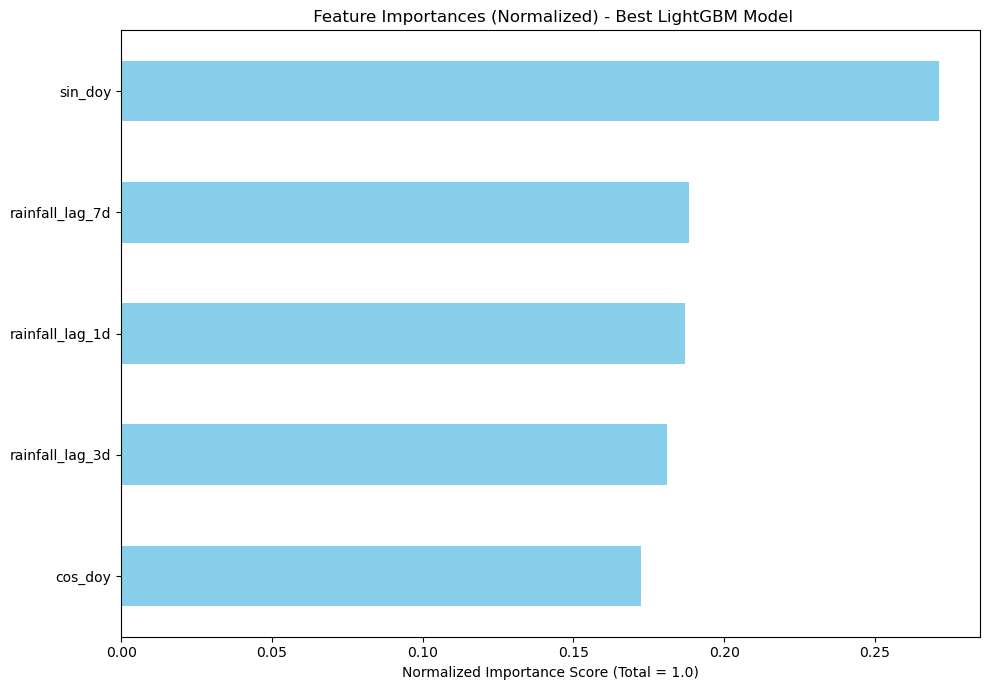


✅ LightGBM Feature Importance Graph Generated.


In [55]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib

# Load the model we just saved/trained
final_lgb_model = joblib.load('final_lgbm_rainfall_model.joblib')

# Assuming X_train_df is available with feature names, or X_train is a DataFrame
# If X_train is a numpy array, replace X_train.columns with your list of feature names (e.g., FEATURES)
try:
    feature_names = X_train.columns
except AttributeError:
    # Fallback assumption: X_train_df is defined or FEATURES list is defined
    try:
        feature_names = X_train_df.columns.tolist()
    except NameError:
        # Final fallback, assuming you have a list named FEATURES
        feature_names = FEATURES

# --- 1. Extract Feature Importances ---

# LightGBM feature importance (split mode is the default and typically fastest/most accurate)
feature_importances = pd.Series(final_lgb_model.feature_importances_, index=feature_names)

# Normalize importance scores for comparison (optional, but good practice)
total_importance = feature_importances.sum()
feature_importances_normalized = feature_importances / total_importance

# --- 2. Plotting the Top Features ---

print("\n📊 Generating LightGBM Feature Importance Plot...")

plt.figure(figsize=(10, 7))
# Plot the top 15 most important features
feature_importances_normalized.nlargest(15).sort_values(ascending=True).plot(kind='barh', color='skyblue')

plt.title(" Feature Importances (Normalized) - Best LightGBM Model")
plt.xlabel("Normalized Importance Score (Total = 1.0)")
plt.tight_layout()
plt.show()

print("\n✅ LightGBM Feature Importance Graph Generated.")

LSTM

In [59]:
import pandas as pd
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from tensorflow.keras.layers import Dropout 

# --- CONFIGURATION ---
TIME_STEPS = 7 
# Assuming X_train_df, X_test_df, y_train, y_test, and chirps are defined.
# We also assume the list of features is in the variable 'FEATURES'.

# New signature: Takes the NumPy array data and its corresponding Pandas Index
def create_sequences(X_data_array, y_data_array, data_index, time_steps):
    Xs, ys = [], []
    
    # 1. Create the temporary DataFrame (X_df) with features, target, and location IDs
    
    # Use the provided index to correctly map to coordinates in chirps
    X_df = chirps.loc[data_index][['lat', 'lon']].copy()
    
    # X_data_array must be converted to a DataFrame to attach feature names
    X_df_features = pd.DataFrame(X_data_array, index=data_index, columns=FEATURES) 
    
    # Merge features and target onto the coordinate DataFrame
    X_df = X_df.merge(X_df_features, left_index=True, right_index=True, how='left')
    X_df['target'] = y_data_array # NumPy array y_data_array is now attached to the correct index
    
    # Loop over each unique (lat, lon) location
    unique_locations = X_df[['lat', 'lon']].drop_duplicates()
    
    for index, location in unique_locations.iterrows():
        lat, lon = location['lat'], location['lon']
        
        # Filter data for the specific location and sort by date index
        location_data = X_df[
            (X_df['lat'] == lat) & (X_df['lon'] == lon)
        ].sort_index() 
        
        # Extract features and targets
        features = location_data[FEATURES].values
        targets = location_data['target'].values
        
        for i in range(len(location_data) - time_steps):
            # Sequence: past 'time_steps' days of features
            Xs.append(features[i:(i + time_steps)])
            # Target: the prediction for the day *after* the sequence ends
            ys.append(targets[i + time_steps])
            
    return np.array(Xs), np.array(ys)


# --- Sequence Creation ---

print(f"⏳ Creating training sequences with time steps = {TIME_STEPS}...")
# CRITICAL CHANGE: Pass X_train_df.index to map coordinates
X_train_sequences, y_train_sequences = create_sequences(X_train, y_train, X_train_df.index, TIME_STEPS)

# Get the number of features 
N_FEATURES = X_train_sequences.shape[2] 

print(f"Original samples: {len(X_train)}. Samples after sequencing: {len(X_train_sequences)}")
print(f"Shape of X_train_sequences: {X_train_sequences.shape}")
print(f"Number of features: {N_FEATURES}")


# --- Step 2 & 3: Model Definition and Training ---

print("\n⚙️ Defining and training LSTM model...")
lstm_model = Sequential([
    # LSTM layer: 64 units, returns only the final output 
    LSTM(64, activation='relu', input_shape=(TIME_STEPS, N_FEATURES)),
    Dropout(0.2), 
    Dense(1)
])

lstm_model.compile(optimizer='adam', loss='mse')

history = lstm_model.fit(
    X_train_sequences, y_train_sequences,
    epochs=30, 
    batch_size=256,
    validation_split=0.1, 
    shuffle=False, 
    verbose=1
)

# --- Step 4: Evaluate the Model ---

print(f"\n⏳ Creating test sequences...")
# CRITICAL CHANGE: Pass X_test_df.index for the test data
X_test_sequences, y_test_sequences = create_sequences(X_test, y_test, X_test_df.index, TIME_STEPS)

print(f"\nEvaluating LSTM on {len(X_test_sequences)} test samples...")
lstm_preds_scaled = lstm_model.predict(X_test_sequences).flatten()

# Calculate R²
lstm_r2 = r2_score(y_test_sequences, lstm_preds_scaled)
lstm_rmse = np.sqrt(mean_squared_error(y_test_sequences, lstm_preds_scaled))

print("=========================================")
print("🧠 LSTM Model Evaluation Scores")
print("=========================================")
print(f"1. RMSE (Root Mean Squared Error):     {lstm_rmse:.6f}")
print(f"2. R² Score (Coefficient of Det.):     {lstm_r2:.6f}")
print("=========================================")

⏳ Creating training sequences with time steps = 7...
Original samples: 1188000. Samples after sequencing: 1153000
Shape of X_train_sequences: (1153000, 7, 5)
Number of features: 5

⚙️ Defining and training LSTM model...


C:\Users\Hayya\anaconda3\envs\xgb-gpu\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/30
4054/4054 ━━━━━━━━━━━━━━━━━━━━ 132s 31ms/step - loss: 0.0051 - val_loss: 0.0049
Epoch 2/30
4054/4054 ━━━━━━━━━━━━━━━━━━━━ 122s 30ms/step - loss: 0.0047 - val_loss: 0.0047
Epoch 3/30
4054/4054 ━━━━━━━━━━━━━━━━━━━━ 131s 32ms/step - loss: 0.0046 - val_loss: 0.0046
Epoch 4/30
4054/4054 ━━━━━━━━━━━━━━━━━━━━ 172s 40ms/step - loss: 0.0045 - val_loss: 0.0045
Epoch 5/30
4054/4054 ━━━━━━━━━━━━━━━━━━━━ 154s 38ms/step - loss: 0.0044 - val_loss: 0.0044
Epoch 6/30
4054/4054 ━━━━━━━━━━━━━━━━━━━━ 157s 39ms/step - loss: 0.0043 - val_loss: 0.0043
Epoch 7/30
4054/4054 ━━━━━━━━━━━━━━━━━━━━ 148s 37ms/step - loss: 0.0043 - val_loss: 0.0043
Epoch 8/30
4054/4054 ━━━━━━━━━━━━━━━━━━━━ 162s 40ms/step - loss: 0.0043 - val_loss: 0.0043
Epoch 9/30
4054/4054 ━━━━━━━━━━━━━━━━━━━━ 162s 40ms/step - loss: 0.0042 - val_loss: 0.0043
Epoch 10/30
4054/4054 ━━━━━━━━━━━━━━━━━━━━ 195s 38ms/step - loss: 0.0042 - val_loss: 0.0043
Epoch 11/30
4054/4054 ━━━━━━━━━━━━━━━━━━━━ 155s 38ms/step - loss: 0.0042 - val_loss: 0.00


Generating LSTM Time Series Chart for location Lat=-0.93, Lon=112.68...


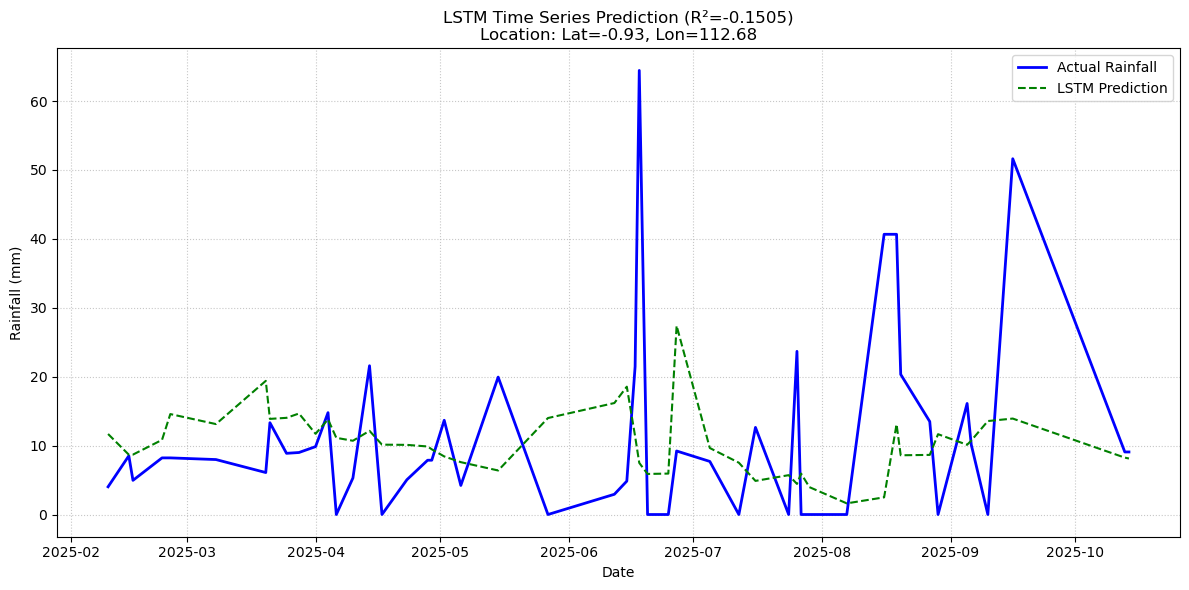


Generating LSTM Distribution Comparison Histogram...


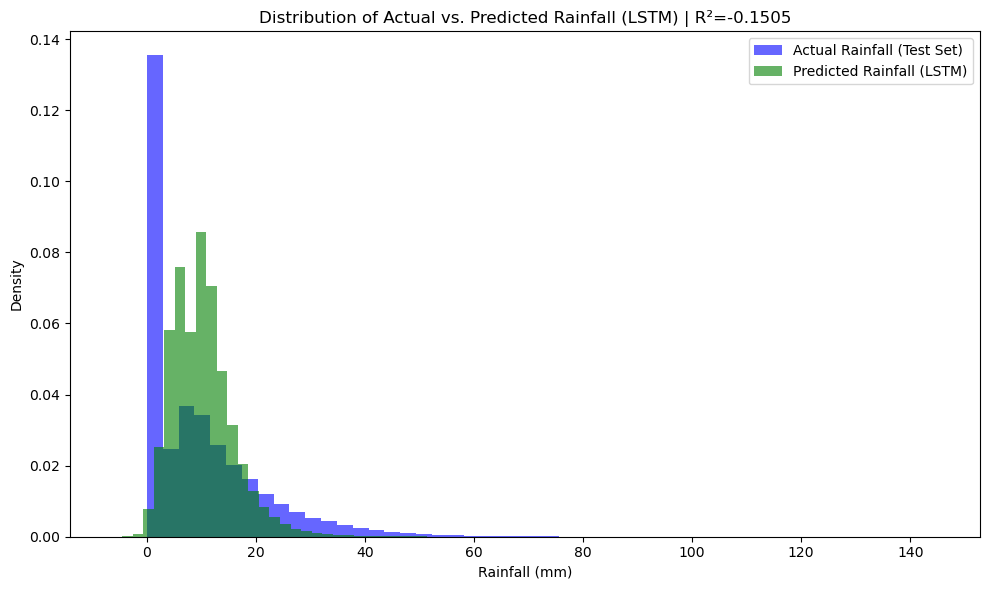


--- Model Comparison Ready ---


In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Model # Needed for Keras models

# --- 1. Prepare Data for Plotting ---

# We need the predictions (lstm_preds_scaled) and actual targets (y_test_sequences)
# from the previous step.

# Since y_test_sequences is a NumPy array, we need to manually reconstruct the DataFrame
# with the corresponding lat/lon/date, which requires mapping back from the sequences.

# The easiest way is to re-run the final part of create_sequences to get the meta-data:
def get_sequences_metadata(X_data_array, y_data_array, data_index, time_steps):
    
    # 1. Create the temporary DataFrame with features, target, and location IDs
    X_df = chirps.loc[data_index][['lat', 'lon', 'date']].copy() # Include date now
    X_df_features = pd.DataFrame(X_data_array, index=data_index, columns=FEATURES) 
    X_df = X_df.merge(X_df_features, left_index=True, right_index=True, how='left')
    X_df['target'] = y_data_array
    
    metadata = []
    
    unique_locations = X_df[['lat', 'lon']].drop_duplicates()
    
    for index, location in unique_locations.iterrows():
        lat, lon = location['lat'], location['lon']
        
        location_data = X_df[
            (X_df['lat'] == lat) & (X_df['lon'] == lon)
        ].sort_index()
        
        # We need the metadata for the *predicted* date, which is the date after the sequence
        for i in range(len(location_data) - time_steps):
            predicted_date_row = location_data.iloc[i + time_steps]
            metadata.append({
                'date': predicted_date_row['date'],
                'lat': lat,
                'lon': lon,
                'actual_scaled': predicted_date_row['target'],
            })
            
    return pd.DataFrame(metadata)


# CRITICAL: Re-create the metadata for the test set predictions
test_meta_df = get_sequences_metadata(X_test, y_test, X_test_df.index, TIME_STEPS)
test_meta_df['predicted_scaled'] = lstm_preds_scaled # Add the LSTM predictions

# --- 2. Inverse Transform to MM (using the fixed scaler) ---

# Re-implementing the DEFINITIVE FIX for the ValueError
rainfall_scaler_fixed = MinMaxScaler()
rainfall_scaler_fixed.min_ = np.array([final_scaler.min_[0]])
rainfall_scaler_fixed.scale_ = np.array([final_scaler.scale_[0]])
rainfall_scaler_fixed.n_features_in_ = 1
rainfall_scaler_fixed.data_min_ = np.array([final_scaler.data_min_[0]])
rainfall_scaler_fixed.data_max_ = np.array([final_scaler.data_max_[0]])
rainfall_scaler_fixed.data_range_ = np.array([final_scaler.data_range_[0]])

test_meta_df['actual_mm'] = rainfall_scaler_fixed.inverse_transform(
    test_meta_df['actual_scaled'].values.reshape(-1, 1)
).flatten()
test_meta_df['predicted_mm'] = rainfall_scaler_fixed.inverse_transform(
    test_meta_df['predicted_scaled'].values.reshape(-1, 1)
).flatten()


# --- 3. Time Series Plot (Zooming on one location) ---

# Select the same location as the previous plot for direct comparison
sample_point = test_meta_df[['lat', 'lon']].drop_duplicates().sample(1, random_state=42)
lat, lon = sample_point.iloc[0]['lat'], sample_point.iloc[0]['lon']

sample_ts = test_meta_df[
    (test_meta_df['lat'] == lat) & (test_meta_df['lon'] == lon)
].sort_values('date')

print(f"\nGenerating LSTM Time Series Chart for location Lat={lat:.2f}, Lon={lon:.2f}...")

plt.figure(figsize=(12, 6))
plt.plot(sample_ts['date'], sample_ts['actual_mm'], 
         label='Actual Rainfall', 
         color='blue', linewidth=2)
plt.plot(sample_ts['date'], sample_ts['predicted_mm'], 
         label='LSTM Prediction', 
         color='green', linestyle='--', linewidth=1.5)

plt.xlabel('Date')
plt.ylabel('Rainfall (mm)')
plt.title(f'LSTM Time Series Prediction (R²={lstm_r2:.4f})\nLocation: Lat={lat:.2f}, Lon={lon:.2f}')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()


# --- 4. Histogram Plot (Distribution Comparison) ---

print("\nGenerating LSTM Distribution Comparison Histogram...")

plt.figure(figsize=(10, 6))
bins = 50
plt.hist(test_meta_df["actual_mm"], bins=bins, density=True, alpha=0.6, label="Actual Rainfall (Test Set)", color='blue')
plt.hist(test_meta_df["predicted_mm"], bins=bins, density=True, alpha=0.6, label="Predicted Rainfall (LSTM)", color='green')
plt.xlabel("Rainfall (mm)")
plt.ylabel("Density")
plt.title(f"Distribution of Actual vs. Predicted Rainfall (LSTM) | R²={lstm_r2:.4f}")
plt.legend()
plt.tight_layout()
plt.show()

print("\n--- Model Comparison Ready ---")
# The final result is the comparison of the LSTM's R² and visual performance against LightGBM.